# *Methodology*

**In this solution I'm going to use the methodology CRISP-DM (Cross-Industry Standard Process for Data Mining) it's because is the most widely used standard methodology in data science and data mining projects.**

the workflow as follow below:

```
         ┌─────────────────────────────────┐
         │         DATA                   │
         └──────────────┬──────────────────┘
                        │
    ┌───────────────────▼───────────────────┐
    │  1.  Business Understanding          │◄──┐
    │                                       │   │
    └───────────────────┬───────────────────┘   │
                        │                       │
    ┌───────────────────▼───────────────────┐   │
    │  2. Data Understanding                │   │
    │                                       │   │
    └───────────────────┬───────────────────┘   │
                        │ ◄──────────────────┐  │
    ┌───────────────────▼───────────────────┐│  │
    │  3. Data Preparation                  ││  │
    │                                       ││  │
    └───────────────────┬───────────────────┘│  │
                        │ ──────────────────►┘  │
    ┌───────────────────▼───────────────────┐   │
    │  4. Modeling                          │   │
    │                                       │   │
    └───────────────────┬───────────────────┘   │
                        │                       │
    ┌───────────────────▼───────────────────┐   │
    │  5. Evaluation                        │───┘
    │                                       │
    └───────────────────┬───────────────────┘
                        │
    ┌───────────────────▼───────────────────┐
    │  6. Deployment                        │
    │                                       │
    └───────────────────────────────────────┘
```

**Except that in this case, there won’t be a model deployment :p hahahaha**

# Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
from pathlib import Path
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 120)
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')
RANDOM_STATE = 42

---
# PHASE 1: *Business Understanding*

*Telecom* is a wireless telecommunications operator. They have years of usage and billing data on roughly 100,000 customers but no in-house machine learning capability.

When a company commissions a business proposal, they usually arrive with a vague sense that *something* needs to improve — margins, retention, growth, customer satisfaction — but no clear view of which lever to pull, which segment to focus on, or even which question to start with. **Choosing the question is the analyst's first job, and the rest of the proposal stands or falls on it.** The dataset rarely points to a single obvious answer; it admits several, and which one you pursue determines the kind of recommendation you can make.

This dataset includes a binary `churn` flag — whether a customer left within 31–60 days after the observation date — and we use churn as the worked example throughout this notebook. But churn is one of many viable targets the data supports. **You may and should explore other targets** — revenue, usage, equipment lifecycle, segment-level behaviour. Pick the question whose answer best supports the proposal you want to make.


- **1.2 Why this market matters**
  - Acquiring a new subscriber costs several times more than keeping one — retention, usage, and ARPU all translate directly into margin.
  - Mature, saturated markets grow by taking customers from competitors or lifting revenue per existing customer.
  - Behaviour signals (usage decline, complaints, equipment ageing) precede both churn and revenue compression by months.

**Questions to think about:**
- What does the telecom market look like in your country or region — who are the major players, what local dynamics (regulation, technology shifts, new entrants) are reshaping churn, and what story can you tell about a specific market you know? A proposal grounded in a local market you can describe concretely is more compelling than one assembled from generic global figures.
- What recent, citable sources can you find that quantify these claims for your target market? Uncited industry numbers will not strengthen your case.
- What share of churn in this market is voluntary (customer-initiated) versus involuntary (non-payment, address change)? Which one can a model meaningfully address?

---
# PHASE 2: *Data Understanding*

## *2.1 Connect to Google Drive*

If you are running this notebook on Google Colab, mount your Drive and `cd` into the folder that contains the dataset.

In [2]:
# Run this cell only on Google Colab.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%cd "/content/drive/MyDrive/Final Assignment"

/content/drive/MyDrive/Final Assignment


In [4]:
current_dir = Path(os.getcwd())
client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

for p in (client_path, record_path):
    print(f"{'OK ' if p.exists() else 'MISSING '} {p}")

OK  /content/drive/MyDrive/Final Assignment/telecom/Client.csv
OK  /content/drive/MyDrive/Final Assignment/telecom/Record.csv


In [5]:
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(f"amount of features in cliente: {client.shape[0]} and data: {client.shape[1]}")
print(f"amount of features in record: {record.shape[0]} and data: {record.shape[1]}")

amount of features in cliente: 100000 and data: 50
amount of features in record: 100000 and data: 51


## *2.2 EDA*

In [ ]:
client.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 50 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  object 
 3   crclscod          100000 non-null  object 
 4   asl_flag          100000 non-null  object 
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  int64  
 16  avg3rev           100

In [ ]:
record.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 51 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   rev_Mean         99643 non-null   float64
 1   mou_Mean         99643 non-null   float64
 2   totmrc_Mean      99643 non-null   float64
 3   da_Mean          99643 non-null   float64
 4   ovrmou_Mean      99643 non-null   float64
 5   ovrrev_Mean      99643 non-null   float64
 6   vceovr_Mean      99643 non-null   float64
 7   datovr_Mean      99643 non-null   float64
 8   roam_Mean        99643 non-null   float64
 9   change_mou       99109 non-null   float64
 10  change_rev       99109 non-null   float64
 11  drop_vce_Mean    100000 non-null  float64
 12  drop_dat_Mean    100000 non-null  float64
 13  blck_vce_Mean    100000 non-null  float64
 14  blck_dat_Mean    100000 non-null  float64
 15  unan_vce_Mean    100000 non-null  float64
 16  unan_dat_Mean    100000 non-null  float

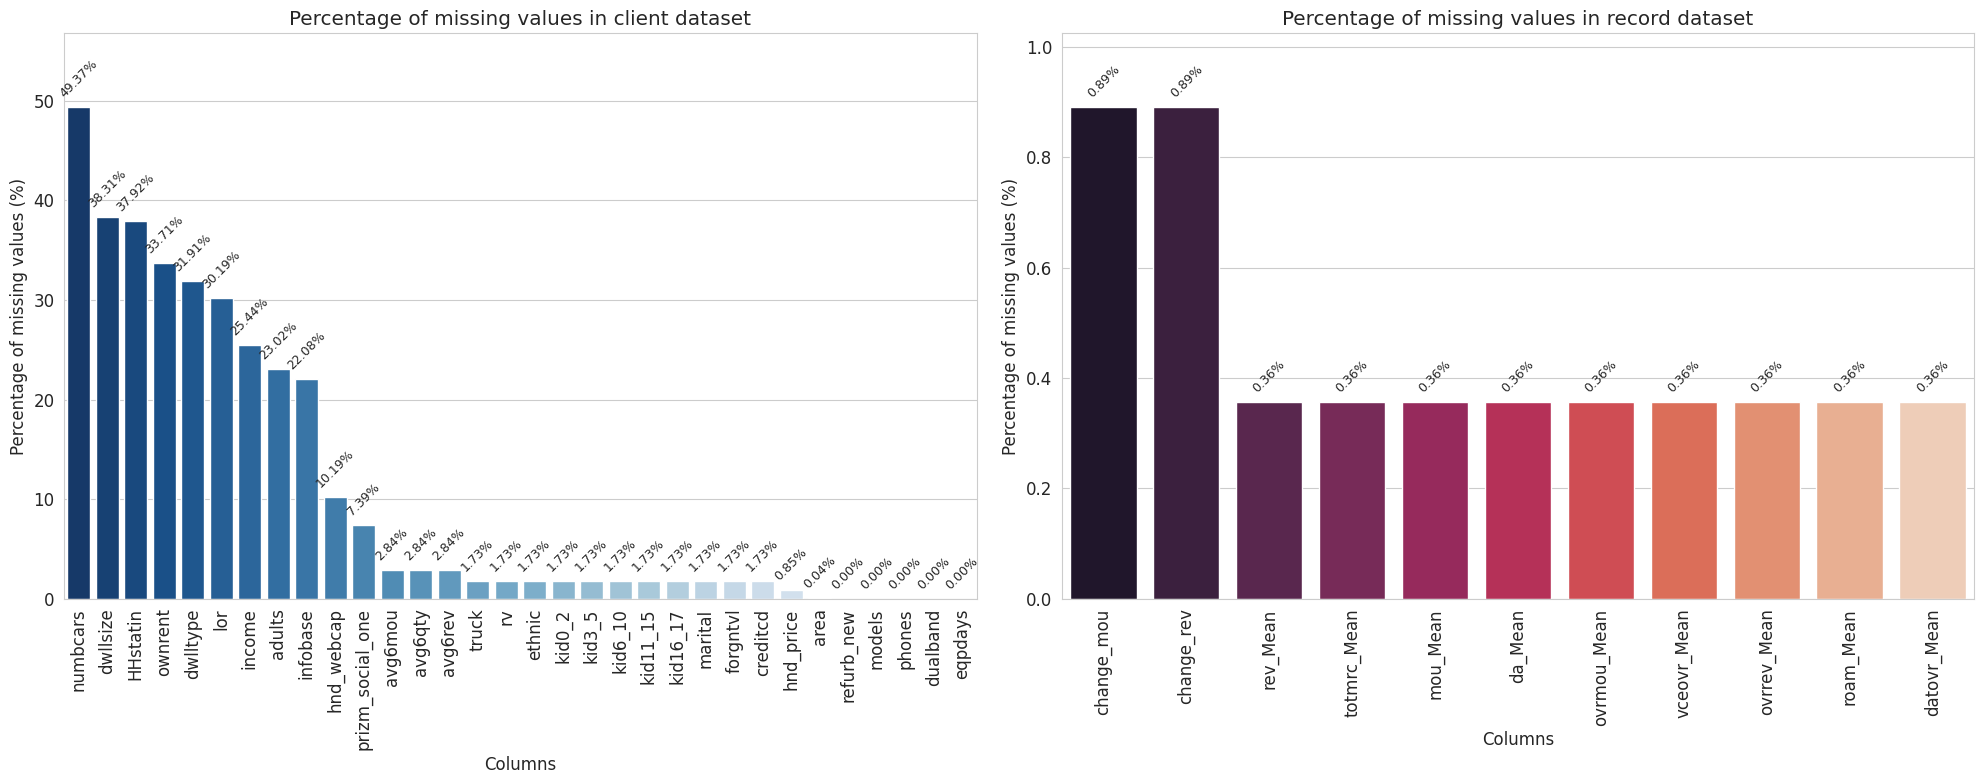

In [6]:

_, axes = plt.subplots(1, 2, figsize=(20, 8))

# Dataset client
missing_count_client = client.isna().sum()
mask = missing_count_client > 0
missing_count_client = missing_count_client[mask]
percentage_missing = pd.DataFrame()
percentage_missing['count'] = ((missing_count_client / client.shape[0]) * 100).sort_values(ascending=False)

# Dataset record
missing_count_record = record.isna().sum()
mask = missing_count_record > 0
missing_count_record = missing_count_record[mask]
percentage_missing_record = pd.DataFrame()
percentage_missing_record['count'] = ((missing_count_record / record.shape[0]) * 100).sort_values(ascending=False)

# plots
sns.barplot(x=percentage_missing.index, y=percentage_missing['count'], palette="Blues_r", ax=axes[0])
axes[0].set_xlabel('Columns')
axes[0].set_ylabel('Percentage of missing values (%)')
axes[0].set_title('Percentage of missing values in client dataset')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90)
axes[0].set_ylim(0, percentage_missing['count'].max() * 1.15)

sns.barplot(x=percentage_missing_record.index, y=percentage_missing_record['count'], palette="rocket", ax=axes[1])
axes[1].set_xlabel('Columns')
axes[1].set_ylabel('Percentage of missing values (%)')
axes[1].set_title('Percentage of missing values in record dataset')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=90)
axes[1].set_ylim(0, percentage_missing_record['count'].max() * 1.15)

# labels dataset client
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.2f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, rotation=45, xytext=(0, 5),
                    textcoords='offset points')

# labels dataset record
for i in axes[1].patches:
    height = i.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.2f}%',
                    (i.get_x() + i.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, rotation=45, xytext=(0, 5),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

In [7]:
# check if there are duplicate date
print("Client shape:", client.shape, "| IDs únicos:", client['Customer_ID'].nunique())
print("Record shape:", record.shape, "| IDs únicos:", record['Customer_ID'].nunique())

Client shape: (100000, 50) | IDs únicos: 100000
Record shape: (100000, 51) | IDs únicos: 100000


In [9]:
df_final = record.merge(client, on='Customer_ID', how='inner')
print(f"Merged: {df_final.shape}")
df_final.head(10)

Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.00,0.00,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.10,9.10,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.00,0.00,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.00,0.00,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.00,0.00,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0
5,82.2750,1312.25,75.000,1.2375,0.00,0.00,0.00,0.0,0.0,156.75,8.1450,52.

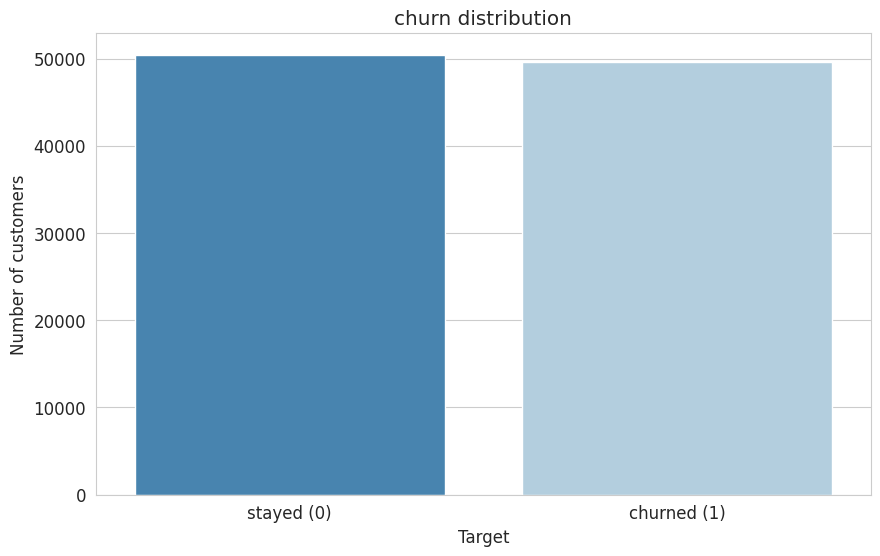

In [10]:
count_target = df_final['churn'].value_counts().sort_index()
lables = ['stayed (0)', 'churned (1)']

sns.barplot(x=lables, y=count_target, palette="Blues_r")
plt.title('churn distribution')
plt.xlabel('Target')
plt.ylabel('Number of customers')
plt.show()

In [11]:
num_cols = df_final.select_dtypes(include=[np.number]).columns.drop(['Customer_ID', 'churn'], errors='ignore')
cat_cols = df_final.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Categorical columns: {cat_cols}")

Categorical columns: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']


In [12]:
for col in cat_cols:
    if df_final[col].nunique() <= 20:
        resumen = df_final.groupby(col, dropna=False)['churn'].agg(['count', 'mean']).sort_values('mean', ascending=False)
        print(f"\n--- {col} ---")
        print(resumen)


--- new_cell ---
          count      mean
new_cell                 
U         66914  0.496951
N         13785  0.496627
Y         19301  0.490285

--- asl_flag ---
          count      mean
asl_flag                 
N         86064  0.509598
Y         13936  0.409300

--- prizm_social_one ---
                  count      mean
prizm_social_one                 
R                  4895  0.527068
NaN                7388  0.515701
T                 14989  0.508373
C                 17018  0.490774
S                 32097  0.490762
U                 23613  0.484818

--- area ---
                               count      mean
area                                          
NaN                               40  0.650000
NORTHWEST/ROCKY MOUNTAIN AREA   4328  0.569085
SOUTH FLORIDA AREA              3332  0.533613
CALIFORNIA NORTH AREA           5913  0.521055
NORTH FLORIDA AREA              4350  0.520000
NEW ENGLAND AREA                5452  0.517425
SOUTHWEST AREA                  6187  0.51

In [13]:
# cat colums
def cramer_corr(x, y):
  confusion_matrix = pd.crosstab(x,y)
  chi2 = chi2_contingency(confusion_matrix)[0]
  n = confusion_matrix.sum().sum()
  phi2 = chi2 / n
  r, k = confusion_matrix.shape
  phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
  rcorr = r - ((r - 1) ** 2) / (n - 1)
  kcorr = k - ((k - 1) ** 2) / (n - 1)
  return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))

In [16]:
cramer_dict = {col: cramer_corr(df_final[col].values, df_final['churn'].values) for col in cat_cols}
results = pd.Series(cramer_dict).to_frame(name='cramer_v').sort_values(by='cramer_v', ascending=False)
results

,cramer_v
crclscod,0.077956
asl_flag,0.069373
hnd_webcap,0.067558
ethnic,0.064143
dualband,0.053677
area,0.050162
refurb_new,0.031598
marital,0.028000
prizm_social_one,0.020736
creditcd,0.016470


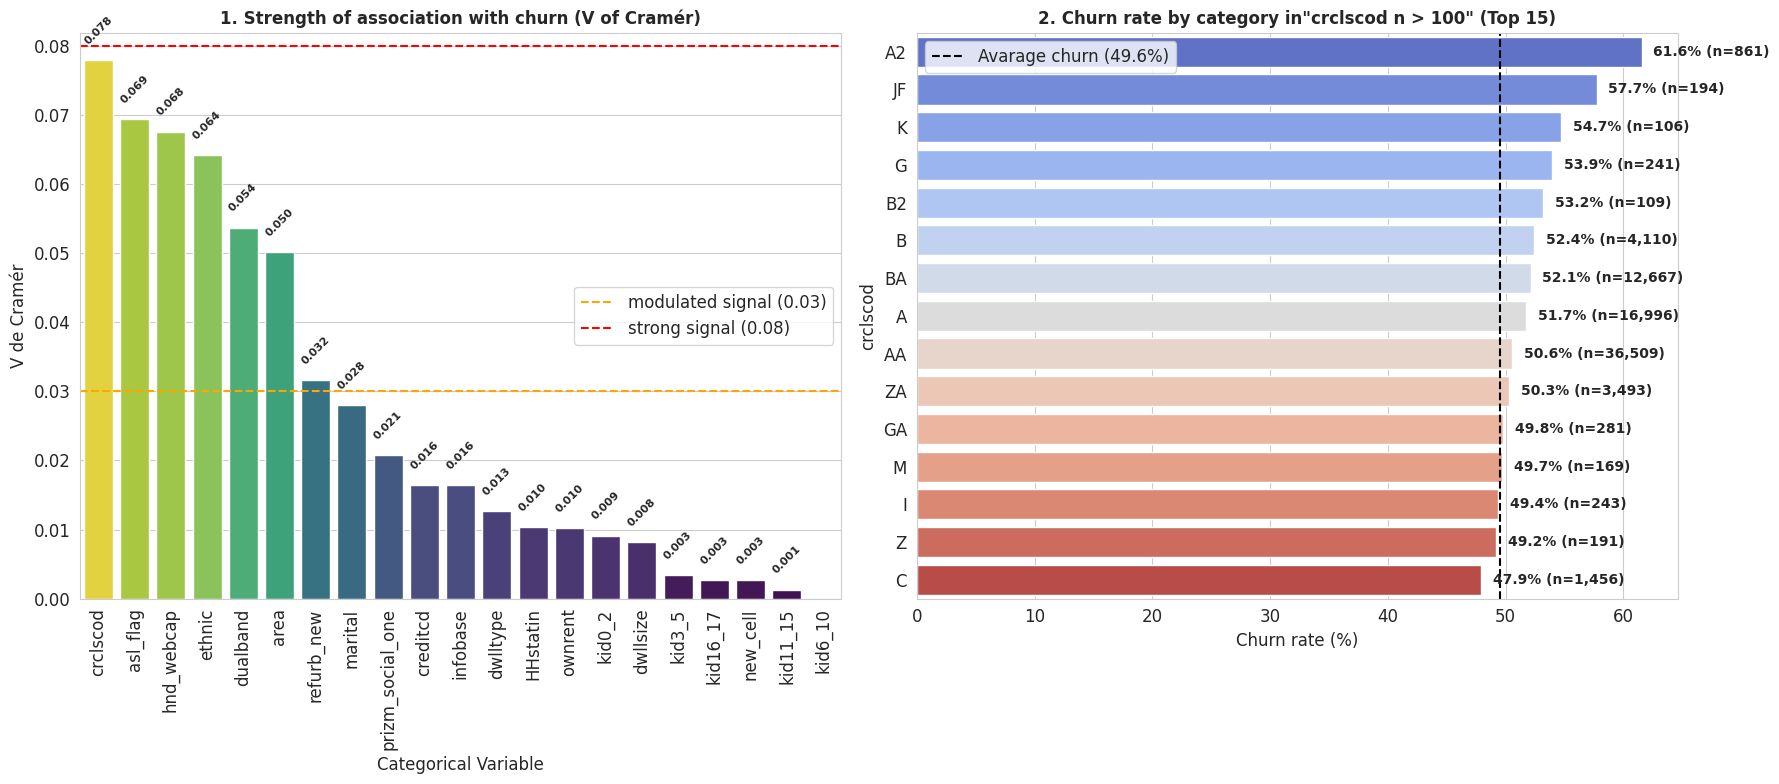

In [17]:
# plots
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.set_style('whitegrid')
sns.barplot(
    x=results.index,
    y=results['cramer_v'],
    ax=axes[0],
    palette='viridis',
    hue=results['cramer_v'],
    legend=False,
)

axes[0].axhline(0.03, color="orange", linestyle='--', label='modulated signal (0.03)')
axes[0].axhline(0.08, color='red', linestyle='--', label='strong signal (0.08)')
axes[0].set_title(
    '1. Strength of association with churn (V of Cramér)',
    fontsize=12,
    fontweight='bold',
)

axes[0].set_xlabel('Categorical Variable')
axes[0].set_ylabel('V de Cramér')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90)
axes[0].legend()

# We iterate directly over the series to obtain the bar index and the scalar value.
for i, v in enumerate(results['cramer_v']):
    if v > 0:
        axes[0].text(i, v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontsize=8, rotation=45, fontweight='bold')

top_var = results.index[0]
avarage_churn = df_final['churn'].mean() * 100

detalle = (
    df_final.fillna({top_var: 'unknown'})
    .groupby(top_var)['churn']
    .agg(rate=lambda x: x.mean() * 100, count='count')
    [lambda df: df['count'] > 100]
    .sort_values(by='rate', ascending=False)
    .head(15)
)

sns.barplot(
    x=detalle['rate'],
    y=detalle.index,
    ax=axes[1],
    palette='coolwarm',
    hue=detalle.index,
    legend=False,
)

axes[1].axvline(
    avarage_churn,
    color='black',
    linestyle='--',
    label=f'Avarage churn ({avarage_churn:.1f}%)',
)
axes[1].set_title(
    f'2. Churn rate by category in"{top_var} n > 100" (Top 15)',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel('Churn rate (%)')
axes[1].set_ylabel(top_var)
axes[1].legend()

# Display the percentage rate and the number of customers (n) for each bar in a reliable way
for i, (rate, count) in enumerate(zip(detalle['rate'], detalle['count'])):
    axes[1].text(
        rate + 1, i, f'{rate:.1f}% (n={count:,})', va='center', fontsize=10, fontweight='bold',
    )

plt.tight_layout()
plt.show()

In [18]:
cat_val_hig = ['crclscod', 'asl_flag', 'hnd_webcap', 'dualband', 'area', 'churn']
analysis_cat = df_final[cat_val_hig]

analysis_cat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   crclscod    100000 non-null  object
 1   asl_flag    100000 non-null  object
 2   hnd_webcap  89811 non-null   object
 3   dualband    99999 non-null   object
 4   area        99960 non-null   object
 5   churn       100000 non-null  int64 
dtypes: int64(1), object(5)
memory usage: 4.6+ MB


In [19]:
for col in cat_val_hig:
  print(f"--- {col} ---")
  print(df_final[col].unique())

--- crclscod ---
['A' 'EA' 'C' 'B' 'BA' 'D' 'G' 'CA' 'I' 'AA' 'J' 'U' 'Z' 'K' 'E' 'E4' 'W'
 'DA' 'Y' 'CC' 'GA' 'D4' 'D5' 'H' 'ZA' 'JF' 'B2' 'IF' 'Z1' 'O' 'M' 'L'
 'U1' 'Z4' 'A2' 'V' 'TP' 'EM' 'C2' 'C5' 'S' 'EC' 'Z5' 'D2' 'GY' 'ZY' 'E2'
 'A3' 'V1' 'EF' 'Z2' 'CY' 'P1' 'ZF']
--- asl_flag ---
['N' 'Y']
--- hnd_webcap ---
['WCMB' 'WC' nan 'UNKW']
--- dualband ---
['Y' 'N' 'T' 'U' nan]
--- area ---
['NORTHWEST/ROCKY MOUNTAIN AREA' 'CHICAGO AREA' 'GREAT LAKES AREA'
 'NEW ENGLAND AREA' 'DALLAS AREA' 'CENTRAL/SOUTH TEXAS AREA'
 'TENNESSEE AREA' 'MIDWEST AREA' 'PHILADELPHIA AREA' 'OHIO AREA'
 'HOUSTON AREA' 'SOUTHWEST AREA' 'NEW YORK CITY AREA'
 'ATLANTIC SOUTH AREA' 'SOUTH FLORIDA AREA' 'CALIFORNIA NORTH AREA'
 'DC/MARYLAND/VIRGINIA AREA' 'NORTH FLORIDA AREA' nan 'LOS ANGELES AREA']
--- churn ---
[1 0]


In [20]:
corr_churn = df_final[num_cols].corrwith(df_final['churn']).abs().sort_values(ascending=False)
print("Top 15 Numéricas más correlacionadas con churn:")
corr_churn.head(15)

Top 15 Numéricas más correlacionadas con churn:


,0
eqpdays,0.112691
hnd_price,0.103184
totmrc_Mean,0.068558
mou_Mean,0.057027
mou_cvce_Mean,0.052042
complete_Mean,0.051740
comp_vce_Mean,0.051574
avg3mou,0.049546
mou_opkv_Mean,0.048896
attempt_Mean,0.048533


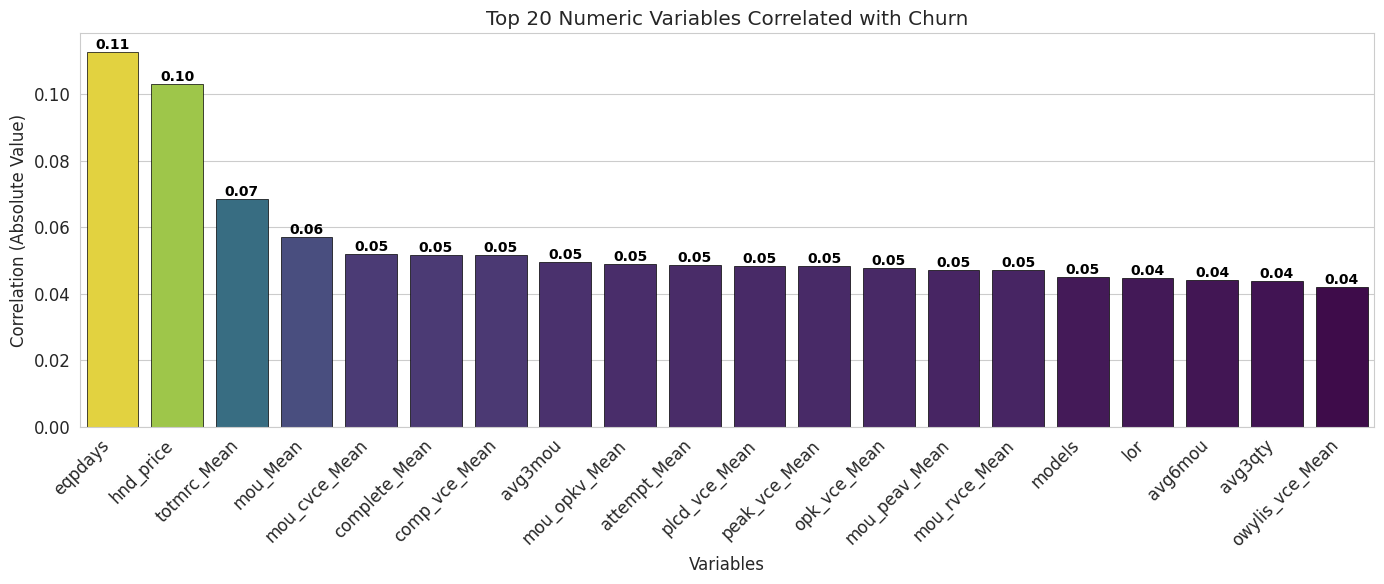

In [21]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=corr_churn.head(20).index,
    y=corr_churn.head(20),
    palette='viridis',
    hue=corr_churn.head(20),
    legend=False,
    edgecolor='black',
    linewidth=0.5,
)

for p in plt.gca().patches:
    plt.gca().annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        fontsize=10, color='black',
        xytext=(0, 5),
        textcoords='offset points',
        fontweight='bold',
    )


plt.xlabel('Variables')
plt.ylabel('Correlation (Absolute Value)')
plt.title('Top 20 Numeric Variables Correlated with Churn')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [22]:
num_val_hig = ['eqpdays', 'hnd_price', 'totmrc_Mean']

In [23]:
df_final['eqpdays'].isna().sum()

np.int64(1)

In [24]:
len(df_final[df_final['eqpdays'] < 0])

133

In [ ]:
df_final['eqpdays'].describe()

,eqpdays
count,99999.000000
mean,391.932309
std,256.482193
min,-5.000000
25%,212.000000
50%,342.000000
75%,530.000000
max,1823.000000


In [25]:
df_final.loc[df_final['eqpdays'] < 0, 'eqpdays'] = 0

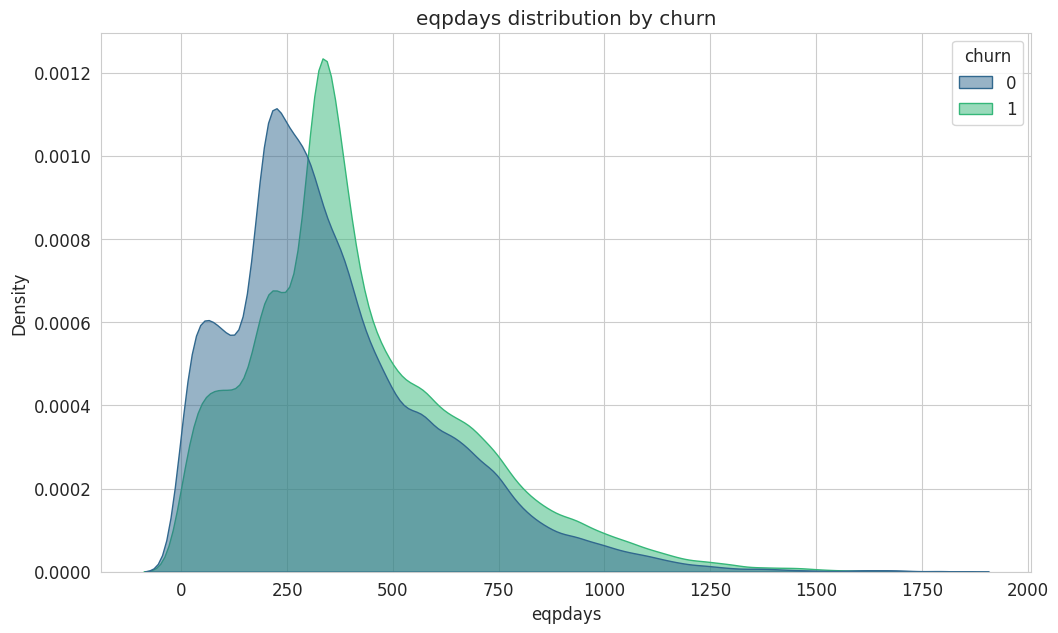

In [26]:
plt.figure(figsize=(12, 7))
sns.kdeplot(
    data=df_final,
    x='eqpdays',
    hue='churn',
    fill=True,
    palette='viridis',
    alpha=0.5,
)

plt.xlabel('eqpdays')
plt.ylabel('Density')
plt.title('eqpdays distribution by churn')
plt.show()

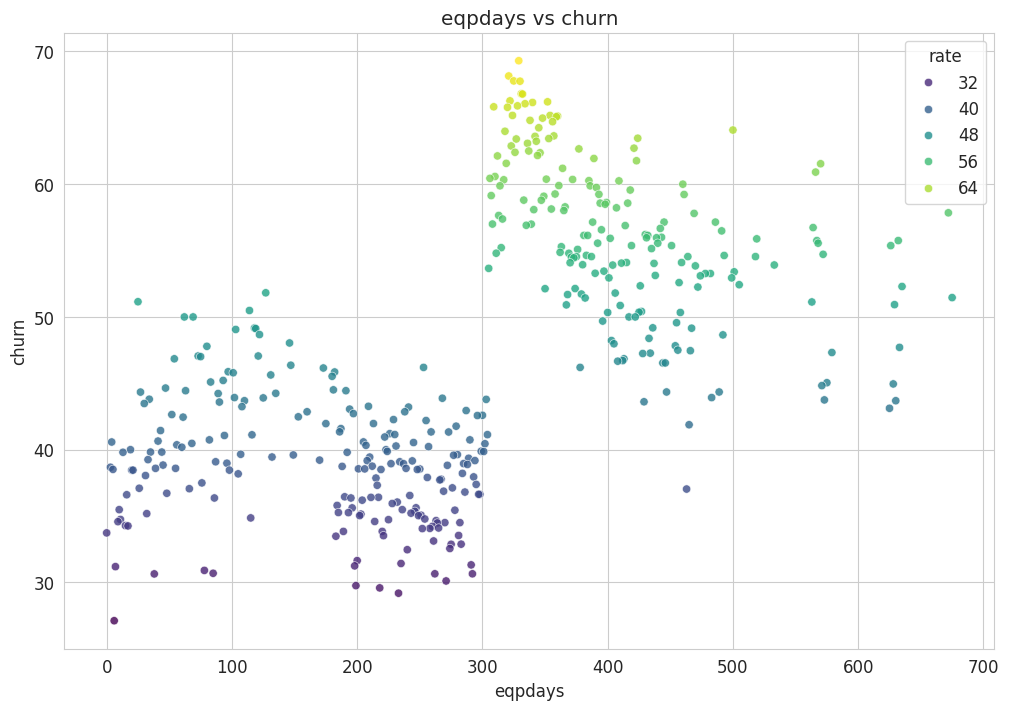

In [27]:
# eqpdays VS churn
eqpdays_analysis = df_final.groupby('eqpdays')['churn'].agg(rate=lambda x: x.mean() * 100, count='count')
eqpdays_analysis = eqpdays_analysis[eqpdays_analysis['count'] > 100].sort_values(by='rate', ascending=False)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=eqpdays_analysis,
    x='eqpdays',
    y='rate',
    hue='rate',
    palette='viridis',
    alpha=0.8,
)

plt.xlabel('eqpdays')
plt.ylabel('churn')
plt.title('eqpdays vs churn')
plt.show()

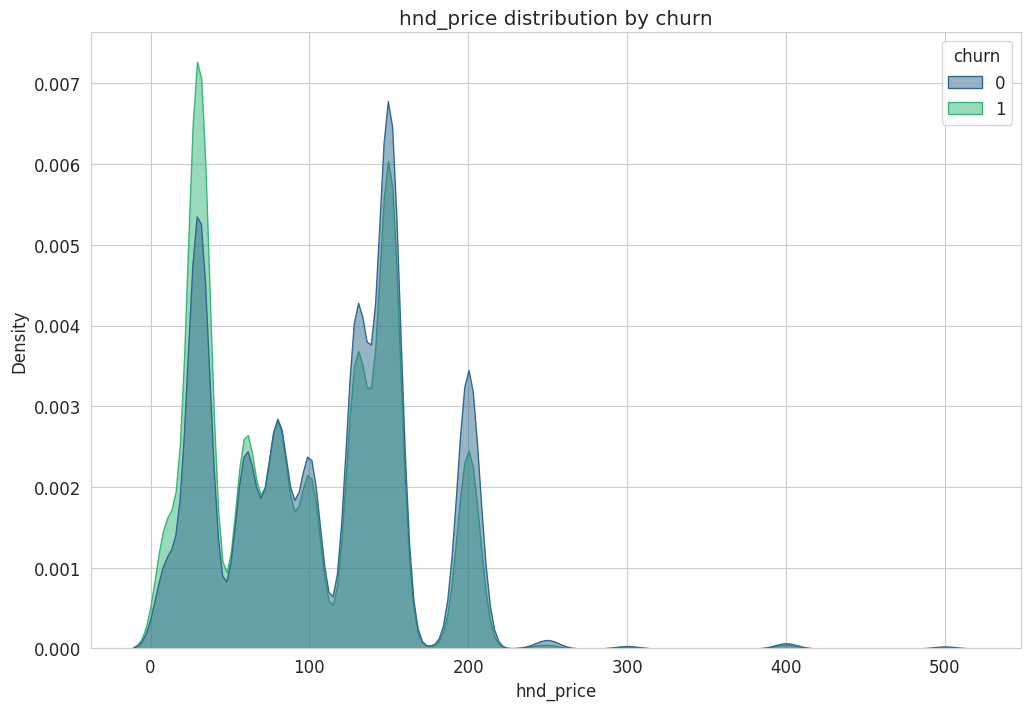

In [28]:
# hnd_price VS churn
plt.figure(figsize = (12, 8))
sns.kdeplot(
    data=df_final,
    x='hnd_price',
    hue='churn',
    fill=True,
    palette='viridis',
    alpha=0.5,
)

plt.xlabel('hnd_price')
plt.ylabel('Density')
plt.title('hnd_price distribution by churn')
plt.show()

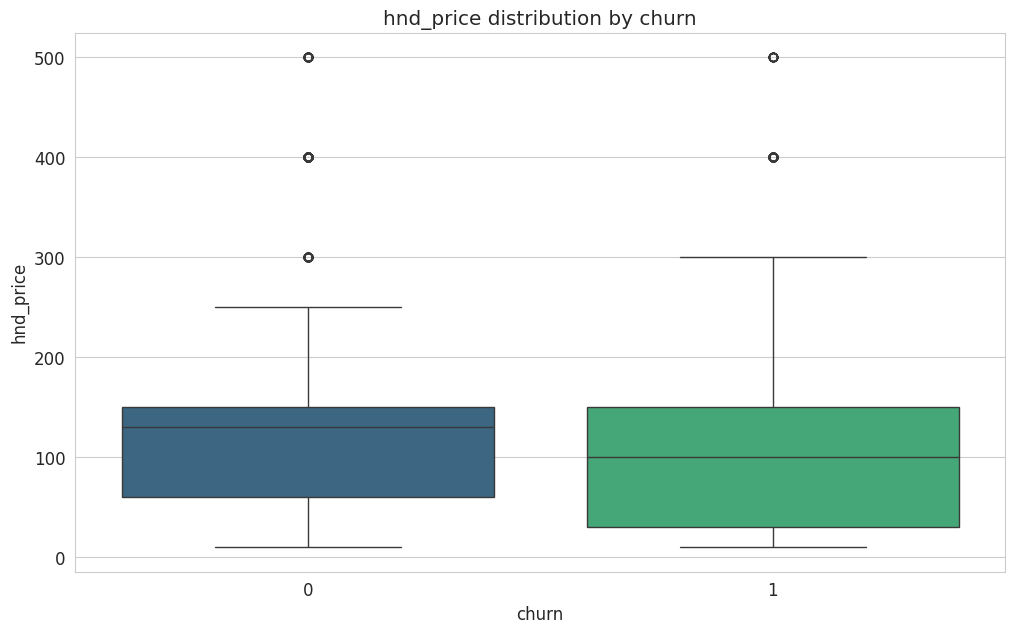

In [29]:
# Prices

plt.figure(figsize=(12, 7))
sns.boxplot(
    data=df_final,
    x='churn',
    y='hnd_price',
    palette='viridis',
)

plt.xlabel('churn')
plt.ylabel('hnd_price')
plt.title('hnd_price distribution by churn')
plt.show()

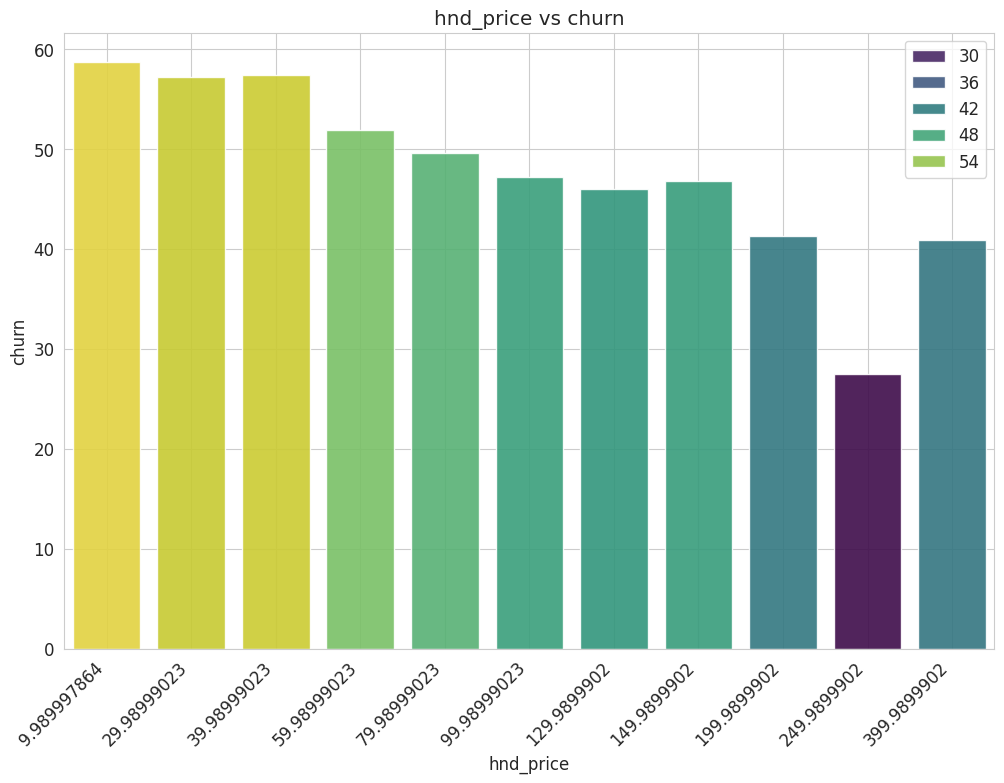

In [30]:
hnd_price_analysis = df_final.groupby('hnd_price')['churn'].agg(rate=lambda x: x.mean() * 100, count='count')
hnd_price_analysis = hnd_price_analysis[hnd_price_analysis['count'] > 100].sort_values(by='rate', ascending=False)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=hnd_price_analysis,
    x='hnd_price',
    y='rate',
    hue='rate',
    palette='viridis',
    alpha=0.9,
)

plt.xlabel('hnd_price')
plt.ylabel('churn')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='x')
plt.legend()
plt.title('hnd_price vs churn')
plt.show()

###2.2.1 EDA (Categorical variable with a numerical variable)

In [31]:
cols = cat_val_hig + num_val_hig + ['Customer_ID']
cols

['crclscod',
 'asl_flag',
 'hnd_webcap',
 'dualband',
 'area',
 'churn',
 'eqpdays',
 'hnd_price',
 'totmrc_Mean',
 'Customer_ID']

Key Variables Selected for Exploratory Data Analysis (EDA)

Based on initial correlation and association (Cramér's V) screening, the following variables exhibit the strongest relationship with customer churn and will be analyzed in detail:

* **`churn` (Target Variable):** Instance of customer churn occurring between **31 and 60 days** after the observation date (`1` = churned, `0` = stayed).
* **`eqpdays` (Equipment Age):** Number of days the subscriber has used their current handset. Higher values indicate aging devices and potential upgrade friction.
* **`hnd_price` (Handset Price):** Current retail price of the subscriber's mobile device, serving as a proxy for device tier and technological capability.
* **`hnd_webcap` (Handset Web Capability):** Internet browsing capability of the subscriber's device (e.g., `WCMB` for full web/multi-band, `WC` for basic web capability, or missing/legacy devices).
* **`dualband` (Dualband Support):** Indicates whether the handset supports dual-band frequencies (`Y` = Yes, `N` = No, `T` = Tri-band), directly impacting network coverage and call reliability.
* **`crclscod` (Credit Class Code):** Internal credit risk classification assigned to the subscriber at account activation (e.g., `AA`, `A`, `BA`, `A2`).
* **`asl_flag` (Account Spending Limit):** Binary indicator (`Y`/`N`) specifying whether the account has a monthly spending cap enabled to prevent unexpected overage charges.
* **`totmrc_Mean` (average monthly charge for a fixed fee or basic subscription):** a charge that is billed or deducted on an ongoing, monthly basis for an active service or subscription.
* **`area` (Geographic Area):** Regional market across the United States where the subscriber's service is registered (e.g., *New York City Area*, *Northwest/Rocky Mountain Area*).

In [32]:
across_analysis = df_final[cols]
across_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   crclscod     100000 non-null  object 
 1   asl_flag     100000 non-null  object 
 2   hnd_webcap   89811 non-null   object 
 3   dualband     99999 non-null   object 
 4   area         99960 non-null   object 
 5   churn        100000 non-null  int64  
 6   eqpdays      99999 non-null   float64
 7   hnd_price    99153 non-null   float64
 8   totmrc_Mean  99643 non-null   float64
 9   Customer_ID  100000 non-null  int64  
dtypes: float64(3), int64(2), object(5)
memory usage: 7.6+ MB


In [33]:
across_analysis.drop('Customer_ID', axis=1).describe(exclude='object')

,churn,eqpdays,hnd_price,totmrc_Mean
count,100000.000000,99999.000000,99153.000000,99643.000000
mean,0.495620,391.935519,101.875763,46.179136
std,0.499983,256.477269,61.005671,23.623489
min,0.000000,0.000000,9.989998,-26.915000
25%,0.000000,212.000000,29.989990,30.000000
50%,0.000000,342.000000,99.989990,44.990000
75%,1.000000,530.000000,149.989990,59.990000
max,1.000000,1823.000000,499.989990,409.990000


In [34]:
across_analysis.describe(include='object', exclude=['float64', 'int64'])

,crclscod,asl_flag,hnd_webcap,dualband,area
count,100000,100000,89811,99999,99960
unique,54,2,3,4,19
top,AA,N,WCMB,Y,NEW YORK CITY AREA
freq,36509,86064,75733,72265,11098


In [35]:
from sklearn.model_selection import train_test_split
import lightgbm as lgb
import shap

In [37]:
X = across_analysis.drop(columns=['Customer_ID', 'churn']).copy()
y = across_analysis['churn'].copy()


cols_object = X.select_dtypes(include=["object", "string"]).columns
X[cols_object] = X[cols_object].astype("category")


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0,
)

params = {
  "max_bin": 512,
  "learning_rate": 0.01,
  "boosting_type": "gbdt",
  "objective": "binary",
  "metric": "binary_logloss",
  "num_leaves": 25,
  "verbose": -1,
  "min_data_in_leaf": 100,
  "boost_from_average": True,
}

model = lgb.LGBMClassifier(
    n_estimators=1000,
    n_jobs=-1,
    random_state=0,
    **params
)


model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    eval_names = ["train", "val"],
    eval_metric = ["precision", "auc"],
    callbacks=[lgb.early_stopping(stopping_rounds=50)]
)

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[946]	train's auc: 0.671472	train's binary_logloss: 0.648385	val's auc: 0.640307	val's binary_logloss: 0.661512


LGBMClassifier(boost_from_average=True, learning_rate=0.01, max_bin=512,
               metric='binary_logloss', min_data_in_leaf=100, n_estimators=1000,
               n_jobs=-1, num_leaves=25, objective='binary', random_state=0,
               verbose=-1)

dict_keys(['train', 'val'])


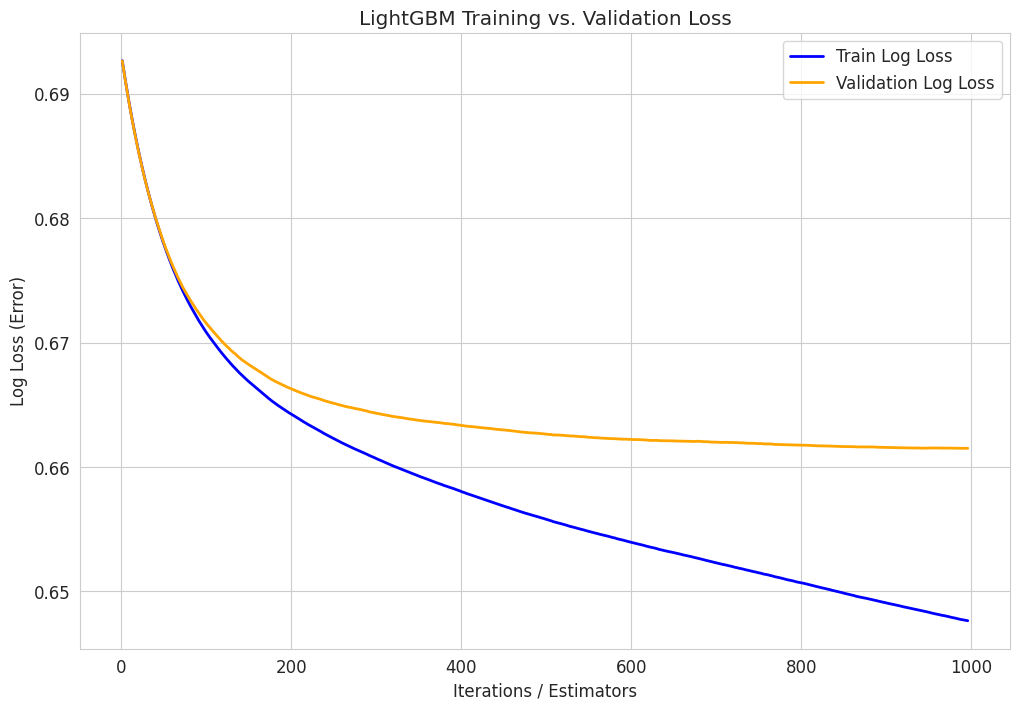

In [38]:
results = model.evals_result_

print(results.keys())
iterations = np.arange(1, len(results["train"]["binary_logloss"]) + 1)

plt.figure(figsize=(12, 8))

sns.lineplot(
    x=iterations,
    y=results["train"]["binary_logloss"],
    label="Train Log Loss",
    color="blue",
    linewidth=2
)

sns.lineplot(
    x=iterations,
    y=results["val"]["binary_logloss"],
    label="Validation Log Loss",
    color="orange",
    linewidth=2
)

plt.ylabel("Log Loss (Error)")
plt.xlabel("Iterations / Estimators")
plt.title("LightGBM Training vs. Validation Loss")
plt.legend()
plt.show()

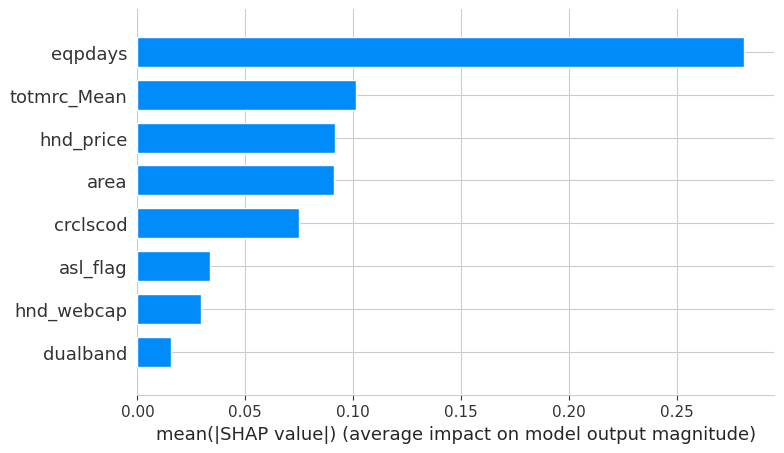

In [39]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X)
shap.summary_plot(shap_values, X, plot_type="bar")

The plot shows which features are most important for predicting churn based on their mean absolute SHAP values. Accordingly, variables such as eqpdays, totmrc_Mean, hnd_price, area, and crclscod are the primary drivers of model output,**confirming that handset age, monthly recurring charges, device tier, regional market, and credit class play a decisive role in subscriber retention.**

###2.2.2 Business Plots

In [40]:
# eqpdays and churn
eqpdays_vs_churn = pd.DataFrame()
df_temp = df_final.dropna(subset=['eqpdays'])
eqpdays_vs_churn['eqpdays_years'] = (df_temp['eqpdays'] / 365)
eqpdays_vs_churn['churn'] = df_final['churn']
eqpdays_vs_churn

,eqpdays_years,churn
0,0.989041,1
1,0.657534,0
2,4.120548,1
3,4.964384,0
4,1.189041,0
...,...,...
99995,2.117808,1
99996,2.287671,0
99997,1.186301,0
99998,0.205479,0


In [41]:
eqpdays_vs_churn.describe(exclude='int64')

,eqpdays_years
count,99999.000000
mean,1.073796
std,0.702677
min,0.000000
25%,0.580822
50%,0.936986
75%,1.452055
max,4.994521


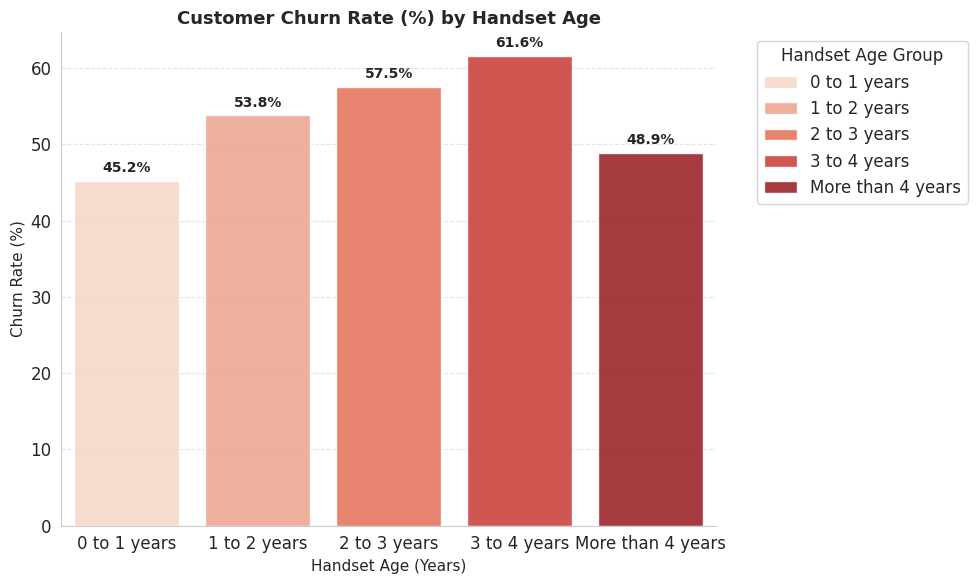

In [42]:
# eqpdays vs churn
labels = ['0 to 1 years', '1 to 2 years', '2 to 3 years', '3 to 4 years', 'More than 4 years']
bins = [-0.01, 1, 2, 3, 4, np.inf]

eqpdays_vs_churn['eqpdays_group'] = pd.cut(
    eqpdays_vs_churn['eqpdays_years'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

grouped_df = (
    eqpdays_vs_churn.groupby('eqpdays_group', observed=False)['churn']
    .agg(churn='mean', count='count')
    .reset_index()
)

grouped_df = grouped_df[grouped_df['count'] > 100]
grouped_df['churn'] = grouped_df['churn'] * 100

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=grouped_df,
    x='eqpdays_group',
    y='churn',
    hue='eqpdays_group',
    palette='Reds',
    alpha=0.9,
    legend=True
)

plt.legend(title='Handset Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=4, fontsize=10, fontweight='bold')

plt.xlabel('Handset Age (Years)', fontsize=11)
plt.ylabel('Churn Rate (%)', fontsize=11)
plt.title('Customer Churn Rate (%) by Handset Age', fontsize=13, fontweight='bold')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
sns.despine()
plt.tight_layout()
plt.show()

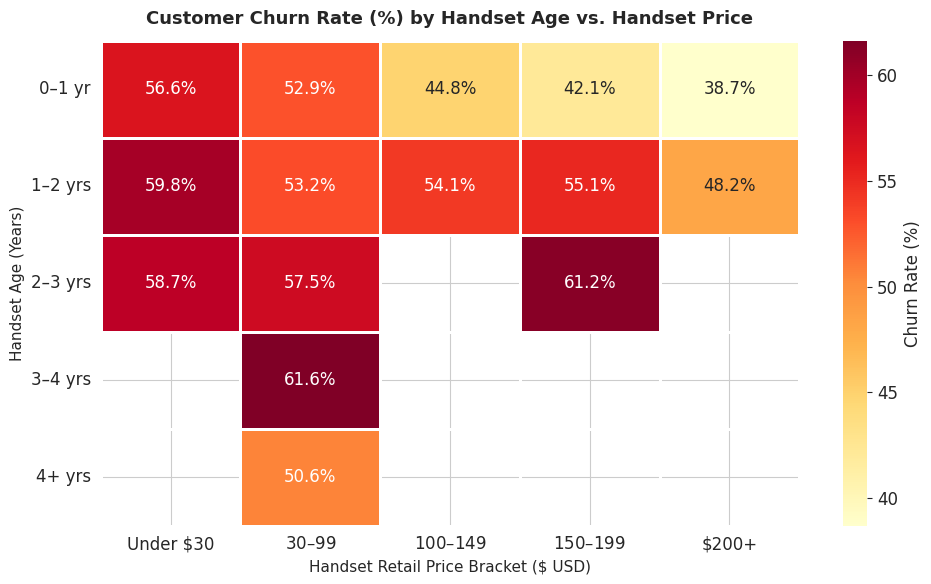

In [43]:
# eqpdays vs hnd_price vs churn
df_hw = df_final[['eqpdays', 'hnd_price', 'churn']].dropna().copy()
df_hw['eqpdays_years'] = df_hw['eqpdays'] / 365.0

age_bins = [-0.01, 1, 2, 3, 4, np.inf]
age_labels = ['0–1 yr', '1–2 yrs', '2–3 yrs', '3–4 yrs', '4+ yrs']

price_bins = [0, 29, 99, 149, 199, np.inf]
price_labels = ['Under $30', '$30–$99', '$100–$149', '$150–$199', '$200+']

df_hw['age_group'] = pd.cut(df_hw['eqpdays_years'], bins=age_bins, labels=age_labels, include_lowest=True)
df_hw['price_group'] = pd.cut(df_hw['hnd_price'], bins=price_bins, labels=price_labels, include_lowest=True)

# 3. Calcular tasa de churn (%) y tamaño de muestra en cada intersección
pivot_churn = df_hw.pivot_table(
    index='age_group',
    columns='price_group',
    values='churn',
    aggfunc='mean',
    observed=False
) * 100

pivot_count = df_hw.pivot_table(
    index='age_group',
    columns='price_group',
    values='churn',
    aggfunc='count',
    observed=False
)

pivot_masked = pivot_churn.where(pivot_count >= 100)

plt.figure(figsize=(10, 6))
ax = sns.heatmap(
    pivot_masked,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=1,
    linecolor='white',
    cbar_kws={'label': 'Churn Rate (%)'}
)


for text in ax.texts:
    text.set_text(text.get_text() + '%')

plt.title('Customer Churn Rate (%) by Handset Age vs. Handset Price', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Handset Retail Price Bracket ($ USD)', fontsize=11)
plt.ylabel('Handset Age (Years)', fontsize=11)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Key Takeaways: Handset Age vs. Retail Price Interaction

* **Sustained High Attrition in Low-Cost Devices:** Subscribers with budget handsets (`Under $30` and `$30–$99`) experience consistently elevated churn across all lifecycle stages, starting at **56.6%** in year one and peaking at **61.6%** in the **3–4 year** bracket.
* **Mid-to-High Tier Retention Buffer:** Premium devices (`$200+`) significantly mitigate early attrition, reducing first-year churn to **38.7%** (nearly 18 percentage points lower than `Under $30` devices) and maintaining the lowest churn rate in year two (**48.2%**).
* **Lifecycle Concentration & Actionable Target:** Virtually no subscribers retain mid-to-high tier devices (`$100+`) beyond three years without upgrading (`n < 30`). Long-term device retention (`3+ years`) is exclusively concentrated in the **`$30–$99`** bracket, making these subscribers the primary target for subsidized handset upgrade campaigns[cite: 10].

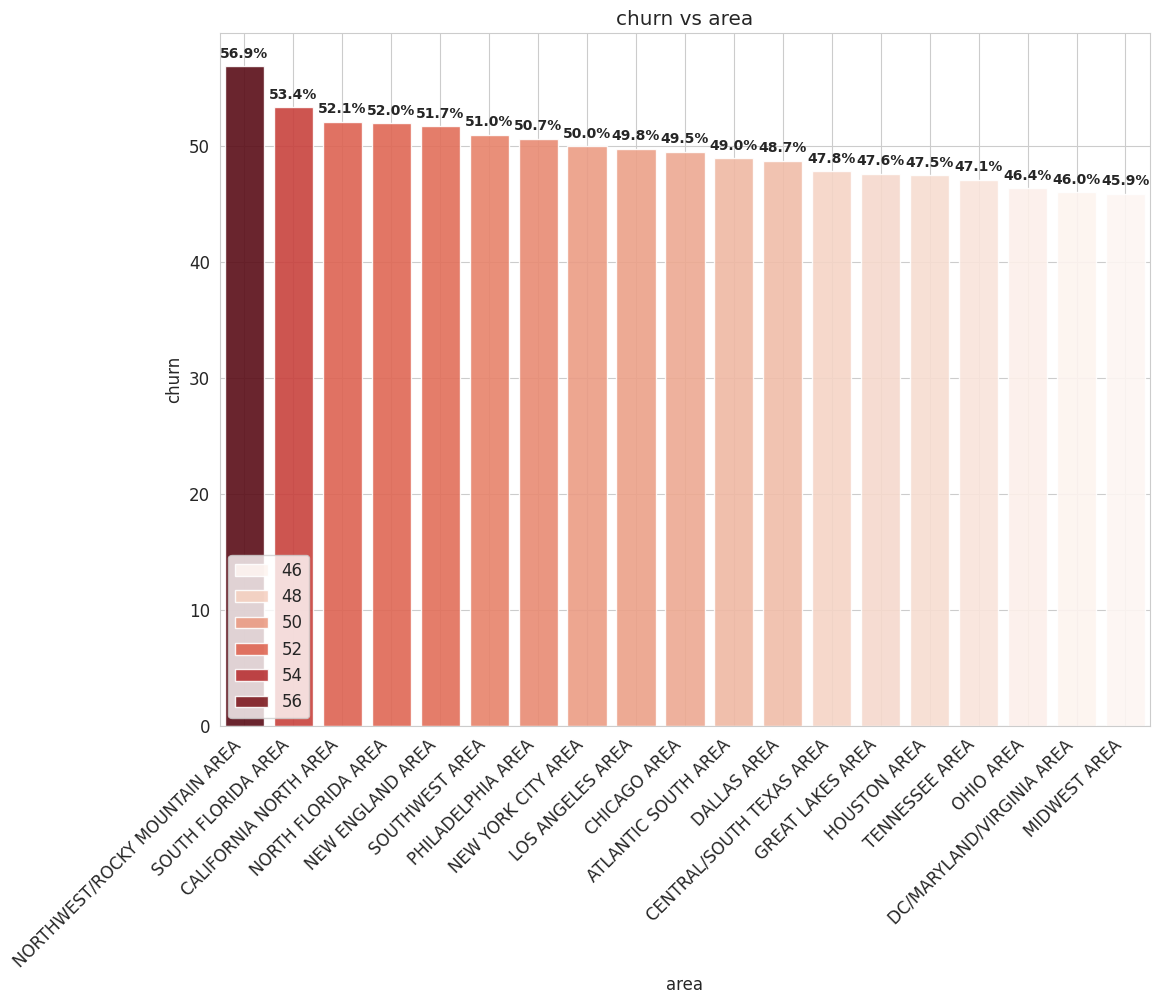

In [44]:
# churn vs area
area_vs_churn = df_final.groupby('area')['churn'].agg(rate=lambda x: x.mean() * 100, count='count').reset_index()
area_vs_churn = area_vs_churn[area_vs_churn['count'] > 100].sort_values(by='rate', ascending=False)

plt.figure(figsize=(12, 9))

ax = sns.barplot(
    data=area_vs_churn,
    x='area',
    y='rate',
    hue='rate',
    palette='Reds',
    alpha=0.9,
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=4, fontsize=10, fontweight='bold')

plt.xlabel('area')
plt.ylabel('churn')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='x')
plt.legend()
plt.title('churn vs area')
plt.show()

In [45]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer()
df_temp_price = df_final.copy()
df_temp_price['hnd_price'] = imputer.fit_transform(df_temp_price[['hnd_price']])
df_temp_price['hnd_price'] = df_temp_price['hnd_price'].astype(int)
df_temp_price['hnd_price'].isna().sum()

np.int64(0)

In [ ]:
df_temp_price['hnd_price'].describe()

,hnd_price
count,100000.000000
mean,100.886740
std,60.746761
min,9.000000
25%,29.000000
50%,99.000000
75%,149.000000
max,499.000000


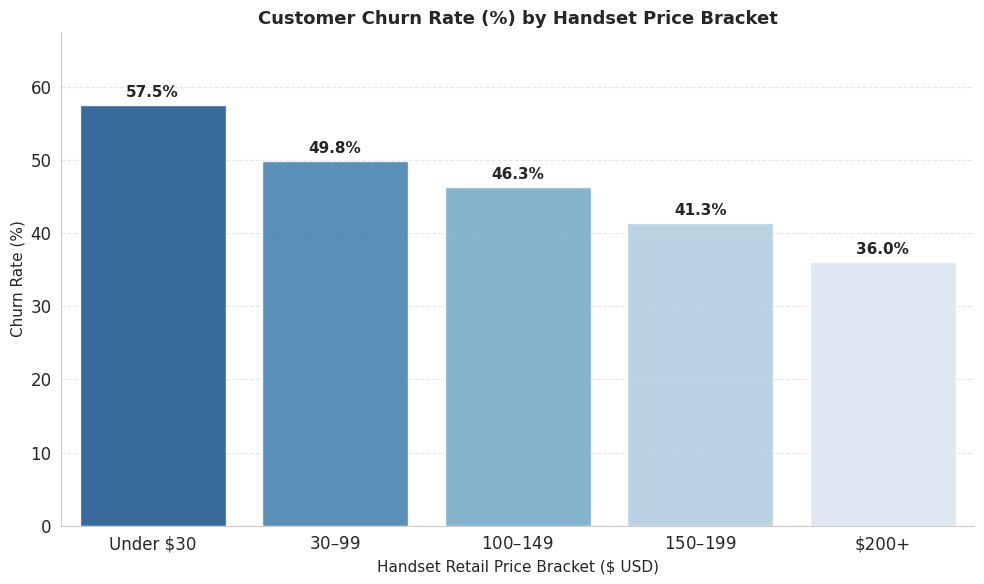

In [46]:
# churn vs hnd_price
bins = [0, 29, 99, 149, 199, np.inf]
labels = ['Under $30', '$30–$99', '$100–$149', '$150–$199', '$200+']

df_temp_price['hnd_price_group'] = pd.cut(
    df_temp_price['hnd_price'],
    bins=bins,
    labels=labels,
    include_lowest=True
)


churn_vs_hnd_price = (
    df_temp_price.groupby('hnd_price_group', observed=False)['churn']
    .agg(rate=lambda x: x.mean() * 100, count='count')
    .reset_index()
)


churn_vs_hnd_price = churn_vs_hnd_price[churn_vs_hnd_price['count'] > 100]
valid_order = churn_vs_hnd_price['hnd_price_group'].tolist()


plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=churn_vs_hnd_price,
    x='hnd_price_group',
    y='rate',
    order=valid_order,
    hue='hnd_price_group',
    hue_order=valid_order,
    palette='Blues_r',
    alpha=0.9,
    legend=False
)


for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=4, fontsize=11, fontweight='bold')

plt.xlabel('Handset Retail Price Bracket ($ USD)', fontsize=11)
plt.ylabel('Churn Rate (%)', fontsize=11)
plt.title('Customer Churn Rate (%) by Handset Price Bracket', fontsize=13, fontweight='bold')
plt.ylim(0, churn_vs_hnd_price['rate'].max() + 10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
sns.despine()
plt.tight_layout()
plt.show()

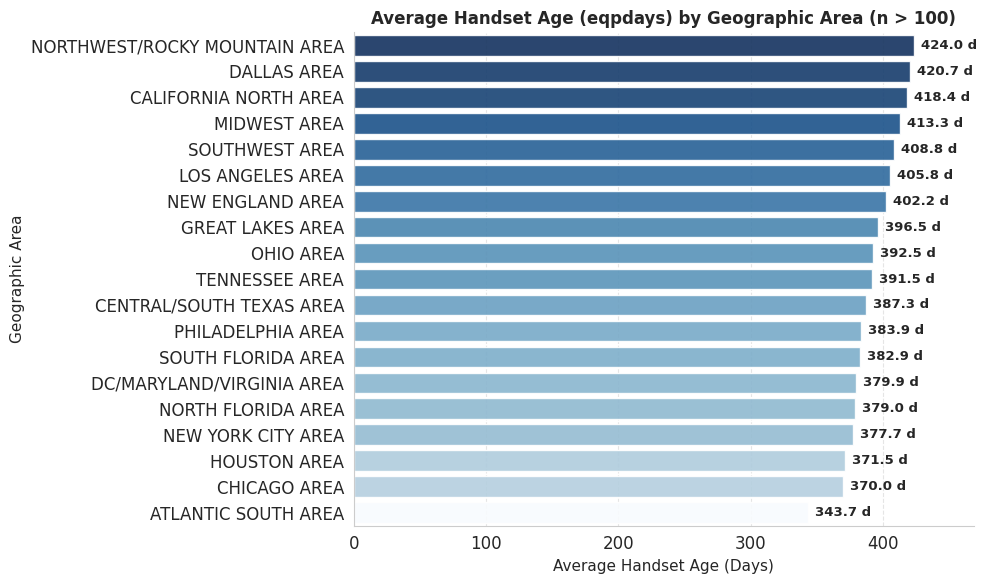

In [47]:
df_final['area'] = df_final['area'].fillna('UNKNOWN')

epqdays_area_analysis = (
    df_final.groupby('area')['eqpdays']
    .agg(mean_days='mean', count='count')
    .sort_values(by='mean_days', ascending=False)
)

epqdays_area_filtered = epqdays_area_analysis[epqdays_area_analysis['count'] > 100].reset_index()
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=epqdays_area_filtered,
    x='mean_days',
    y='area',
    hue='mean_days',
    palette='Blues',
    alpha=0.9,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f d', padding=5, fontsize=9.5, fontweight='bold')

plt.xlabel('Average Handset Age (Days)', fontsize=11)
plt.ylabel('Geographic Area', fontsize=11)
plt.title('Average Handset Age (eqpdays) by Geographic Area (n > 100)', fontsize=12, fontweight='bold')
plt.xlim(0, epqdays_area_filtered['mean_days'].max() + 45)
plt.grid(axis='x', linestyle='--', alpha=0.5)
sns.despine()
plt.tight_layout()
plt.show()

Key Takeaways: Average Handset Age by Geographic Area

* **Nationwide Aging Fleet:** Across all major geographic markets (`n > 100`), average handset age exceeds the critical **300-day churn threshold**, ranging from **343.7 days** in *Atlantic South* to **424.0 days** (~14 months) in *Northwest/Rocky Mountain*[cite: 9].
* **Pilot Market Prioritization:** While device aging is a systemic issue rather than an isolated regional anomaly, markets with the oldest active handsets—specifically **Northwest/Rocky Mountain (424.0 days)**, **Dallas (420.7 days)**, and **California North (418.4 days)**—represent ideal pilot regions for targeted handset upgrade incentives[cite: 9].

In [ ]:
epqdays_area_analysis

,mean_days,count
area,,
NORTHWEST/ROCKY MOUNTAIN AREA,423.976201,4328
DALLAS AREA,420.692776,5426
CALIFORNIA NORTH AREA,418.425841,5913
MIDWEST AREA,413.325559,6346
SOUTHWEST AREA,408.779214,6187
LOS ANGELES AREA,405.761754,6636
NEW ENGLAND AREA,402.204696,5452
GREAT LAKES AREA,396.461390,4649
OHIO AREA,392.479913,4580


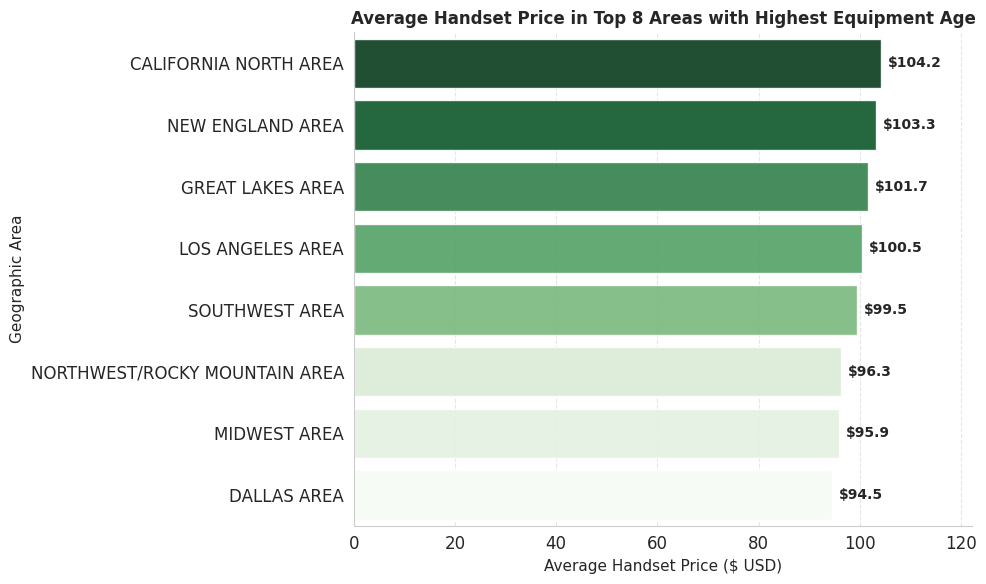

In [48]:
# areas vs hnd_price
high_areas = epqdays_area_analysis.index[:8].tolist()

hdn_prices_analysis = (
    df_final[df_final['area'].isin(high_areas)]
    .groupby('area')['hnd_price']
    .agg(mean_price='mean', count='count')
    .sort_values(by='mean_price', ascending=False)
)


hdn_prices = hdn_prices_analysis[hdn_prices_analysis['count'] > 100].reset_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=hdn_prices,
    x='mean_price',
    y='area',
    hue='mean_price',
    palette='Greens',
    alpha=0.9,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='$%.1f', padding=5, fontsize=10, fontweight='bold')

plt.xlabel('Average Handset Price ($ USD)', fontsize=11)
plt.ylabel('Geographic Area', fontsize=11)
plt.title('Average Handset Price in Top 8 Areas with Highest Equipment Age', fontsize=12, fontweight='bold')
plt.xlim(0, hdn_prices['mean_price'].max() + 18)
plt.grid(axis='x', linestyle='--', alpha=0.5)
sns.despine()
plt.tight_layout()
plt.show()

**This plot show that areas vs hnd_price don't contribute much to data analysis.**

In [49]:
print(df_final['refurb_new'].isna().sum())
print(df_final['refurb_new'].unique())

1
['N' 'R' nan]


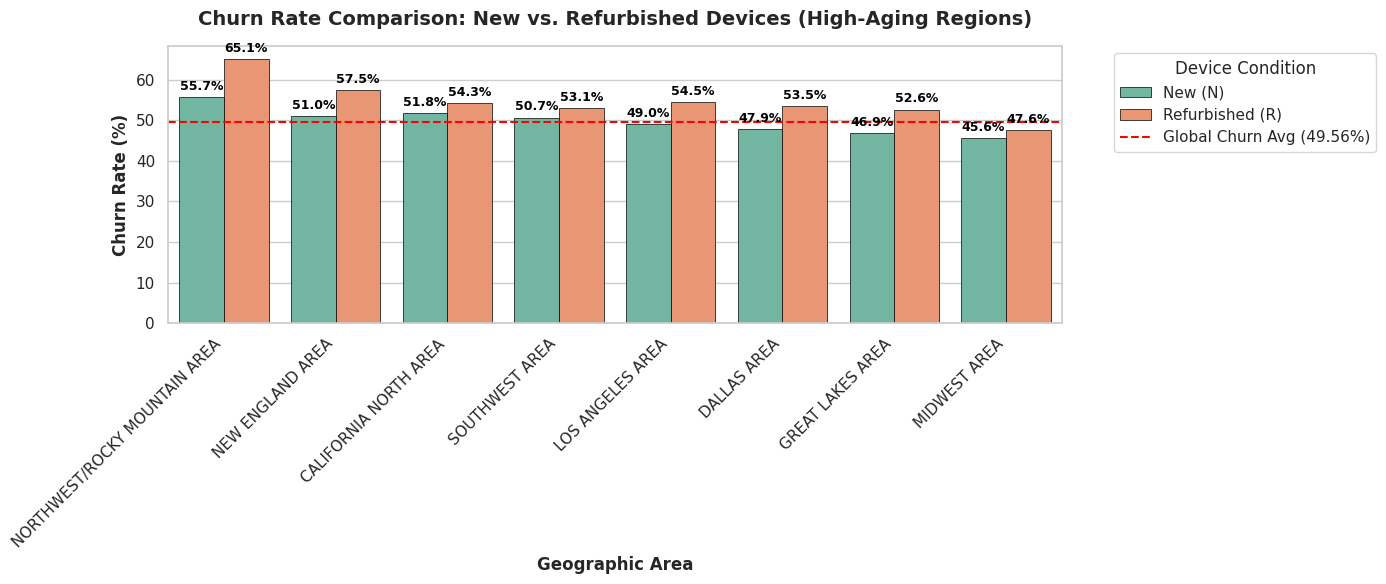

In [50]:
N_data = df_final[(df_final['area'].isin(high_areas)) & (df_final['refurb_new'] == 'N')].groupby('area')['churn'].agg(rate=lambda x: x.mean() * 100, count='count').reset_index()
N_data = N_data[N_data['count'] > 100]
N_data['Device Type'] = 'New (N)'

R_data = df_final[(df_final['area'].isin(high_areas)) & (df_final['refurb_new'] == 'R')].groupby('area')['churn'].agg(rate=lambda x: x.mean() * 100, count='count').reset_index()
R_data = R_data[R_data['count'] > 100]
R_data['Device Type'] = 'Refurbished (R)'


plot_df = pd.concat([N_data, R_data], ignore_index=True)
order_areas = plot_df.groupby('area')['rate'].mean().sort_values(ascending=False).index
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=plot_df,
    x='area',
    y='rate',
    hue='Device Type',
    palette='Set2',
    order=order_areas,
    edgecolor='black',
    linewidth=0.5
)


overall_average = df_final['churn'].mean() * 100
plt.axhline(overall_average, color='red', linestyle='--', linewidth=1.5, label=f'Global Churn Avg ({overall_average:.2f}%)')
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, color='black',
                    xytext=(0, 3), textcoords='offset points',
                    fontweight='bold')


plt.title('Churn Rate Comparison: New vs. Refurbished Devices (High-Aging Regions)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Geographic Area', fontsize=12, fontweight='bold')
plt.ylabel('Churn Rate (%)', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Device Condition', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

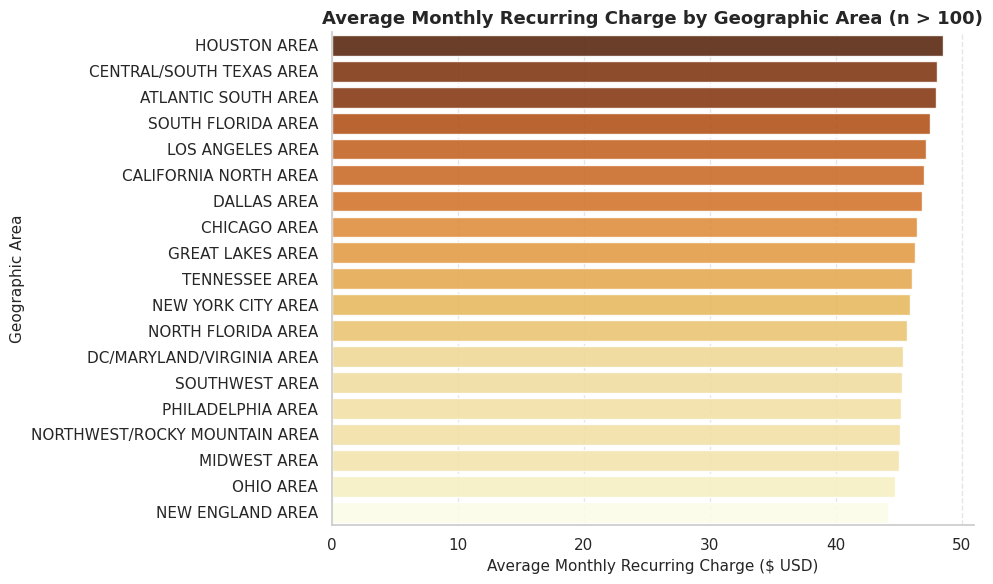

In [51]:
# Average Monthly Recurring Charge (totmrc_Mean) by Geographic Area
area_vs_totmrc = (
    df_final.groupby('area')['totmrc_Mean']
    .agg(mean_charge='mean', count='count')
    .reset_index()
)
area_vs_totmrc = area_vs_totmrc[area_vs_totmrc['count'] > 100].sort_values(by='mean_charge', ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=area_vs_totmrc,
    x='mean_charge',
    y='area',
    hue='mean_charge',
    palette='YlOrBr',
    legend=False,
    alpha=0.9
)

plt.xlabel('Average Monthly Recurring Charge ($ USD)', fontsize=11)
plt.ylabel('Geographic Area', fontsize=11)
plt.title('Average Monthly Recurring Charge by Geographic Area (n > 100)', fontsize=13, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
sns.despine()
plt.tight_layout()
plt.show()

**This plot show that Average Monthly Recurring Charge (totmrc_Mean) by Geographic Areae don't contribute much to data analysis.**

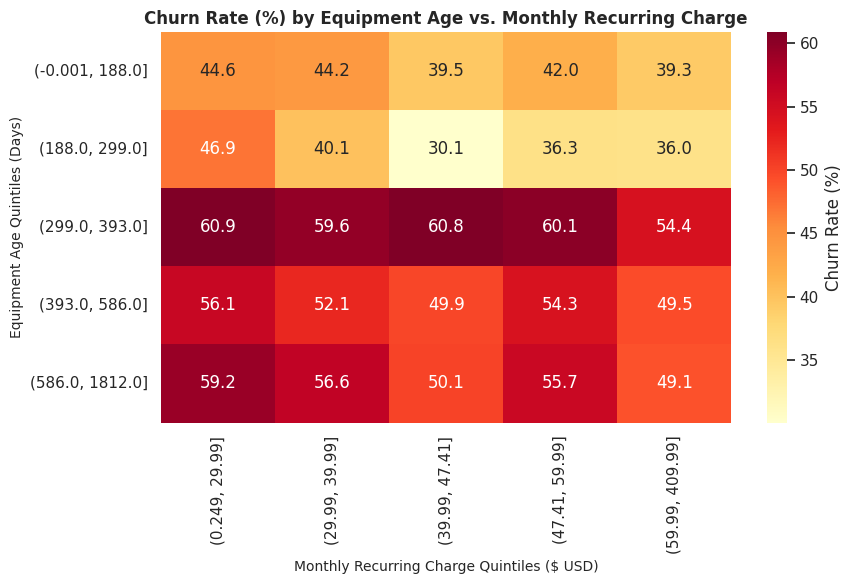

In [52]:
df_temp = df_final[['eqpdays', 'totmrc_Mean', 'churn']].dropna().copy()
df_temp = df_temp[df_temp['totmrc_Mean'] > 0]

df_temp['eqp_group'] = pd.qcut(df_temp['eqpdays'], q=5, duplicates='drop')
df_temp['mrc_group'] = pd.qcut(df_temp['totmrc_Mean'], q=5, duplicates='drop')

pivot_churn = df_temp.pivot_table(
    index='eqp_group',
    columns='mrc_group',
    values='churn',
    aggfunc='mean',
    observed=False
) * 100

plt.figure(figsize=(9, 6))
sns.heatmap(
    pivot_churn,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title('Churn Rate (%) by Equipment Age vs. Monthly Recurring Charge', fontsize=12, fontweight='bold')
plt.xlabel('Monthly Recurring Charge Quintiles ($ USD)', fontsize=10)
plt.ylabel('Equipment Age Quintiles (Days)', fontsize=10)
plt.tight_layout()
plt.show()

### 2.2.3 Features not yet seen

**Given all of the above, it feels like something is missing; therefore, we will incorporate additional variables, beyond the 8 previously identified.**

In [53]:
df_final['crclscod'].unique()

array(['A', 'EA', 'C', 'B', 'BA', 'D', 'G', 'CA', 'I', 'AA', 'J', 'U',
       'Z', 'K', 'E', 'E4', 'W', 'DA', 'Y', 'CC', 'GA', 'D4', 'D5', 'H',
       'ZA', 'JF', 'B2', 'IF', 'Z1', 'O', 'M', 'L', 'U1', 'Z4', 'A2', 'V',
       'TP', 'EM', 'C2', 'C5', 'S', 'EC', 'Z5', 'D2', 'GY', 'ZY', 'E2',
       'A3', 'V1', 'EF', 'Z2', 'CY', 'P1', 'ZF'], dtype=object)

In [54]:
comparativa = (
    df_final[df_final['crclscod'].isin(['A2', 'JF', 'AA', 'A', 'EA', 'E4', 'D5'])]
    .groupby('crclscod')
    .agg(
        clientes=('Customer_ID', 'count'),
        churn_rate=('churn', lambda x: x.mean() * 100),
        con_limite_gasto=('asl_flag', lambda x: (x == 'Y').mean() * 100),
        con_tarjeta_cred=('creditcd', lambda x: (x == 'Y').mean() * 100),
        antiguedad_meses=('months', 'mean'),
        factura_mensual=('rev_Mean', 'mean'),
        dias_equipo=('eqpdays', 'mean'),
    )
    .sort_values(by='churn_rate', ascending=False)
)

display(comparativa.round(1))

,clientes,churn_rate,con_limite_gasto,con_tarjeta_cred,antiguedad_meses,factura_mensual,dias_equipo
crclscod,,,,,,,
A2,861,61.6,0.0,82.5,21.4,43.0,542.5
JF,194,57.7,69.6,62.9,12.7,59.8,306.4
A,16996,51.7,0.2,79.8,29.4,52.3,565.2
AA,36509,50.6,0.2,73.0,15.4,53.3,373.2
EA,6419,41.0,49.6,55.5,15.7,72.6,302.9
E4,833,30.6,92.4,41.3,10.8,79.4,194.9
D5,114,19.3,95.6,42.1,9.8,73.5,203.9


In [55]:
variables_clave = ['eqpdays', 'months', 'change_mou', 'rev_Mean', 'drop_vce_Mean']
display(df_final.groupby('churn')[variables_clave].median().T)

churn,0,1
eqpdays,310.00000,366.00
months,16.00000,17.00
change_mou,-3.00000,-10.00
rev_Mean,48.87625,47.49
drop_vce_Mean,3.00000,3.00


In [58]:

bins_eqp = [0, 180, 365, 540, 730, 2000]
labels_eqp = ['0-6 months', '6-12 months', '12-18 months', '18-24 months', '+24 months']

df_temp = df_final[df_final['eqpdays'] >= 0].copy()
df_temp['rango_equipo'] = pd.cut(df_temp['eqpdays'], bins=bins_eqp, labels=labels_eqp)

churn_equipo = df_temp.groupby('rango_equipo', observed=False)['churn'].agg(
    rate=lambda x: x.mean() * 100,
    count='count'
).reset_index()

display(churn_equipo.round(1))

,rango_equipo,rate,count
0,0-6 months,41.8,18161
1,6-12 months,47.0,36356
2,12-18 months,53.7,21138
3,18-24 months,54.0,13367
4,+24 months,57.9,10811


In [59]:
def churn_plot(col, kind='auto', q=10, bins=None, min_n=200):
    s = df_final[col]
    if kind == 'auto':
        kind = 'cat' if s.dtype == 'object' else ('disc' if s.nunique() <= 15 else 'num')

    n_miss = s.isna().sum()
    if n_miss:
        print(f"Nulos en {col}: {n_miss:,} -> churn {df_final.loc[s.isna(), 'churn'].mean():.1%}")

    if kind == 'cat':
        g = df_final.groupby(s.fillna('NaN'))['churn'].agg(['mean', 'count'])
        g = g[g['count'] >= min_n].sort_values('mean')
    elif kind == 'disc':
        g = df_final.groupby(s)['churn'].agg(['mean', 'count'])
        g = g[g['count'] >= min_n].sort_index()
    else:
        grp = pd.cut(s, bins) if bins is not None else pd.qcut(s, q, duplicates='drop')
        g = df_final.groupby(grp, observed=True)['churn'].agg(['mean', 'count'])
        g = g[g['count'] >= min_n]

    labels = [str(i) for i in g.index]
    rate = g['mean'] * 100
    base = df_final['churn'].mean() * 100
    colors = ['#d62728' if r > base else '#1f77b4' for r in rate]

    if kind == 'cat':
        fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(g))))
        ax.barh(labels, rate, color=colors)
        ax.axvline(base, color='black', ls='--', label=f'Churn global ({base:.1f}%)')
        for i, (r, n) in enumerate(zip(rate, g['count'])):
            ax.text(r + 0.5, i, f"{r:.1f}% (n={n:,})", va='center', fontsize=9)
        ax.set_xlim(0, rate.max() + 15)
        ax.set_xlabel('Churn (%)')
    else:
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.bar(range(len(g)), rate, color=colors)
        ax.axhline(base, color='black', ls='--', label=f'Churn global ({base:.1f}%)')
        ax.set_xticks(range(len(g)))
        ax.set_xticklabels(labels, rotation=45, ha='right')
        for i, (r, n) in enumerate(zip(rate, g['count'])):
            ax.text(i, r + 0.5, f"{r:.1f}%\nn={n:,}", ha='center', fontsize=8)
        ax.set_ylim(0, rate.max() + 10)
        ax.set_ylabel('Churn (%)')

    ax.set_title(f'Churn by {col}', fontweight='bold')
    ax.legend()
    sns.despine()
    plt.tight_layout()
    plt.show()

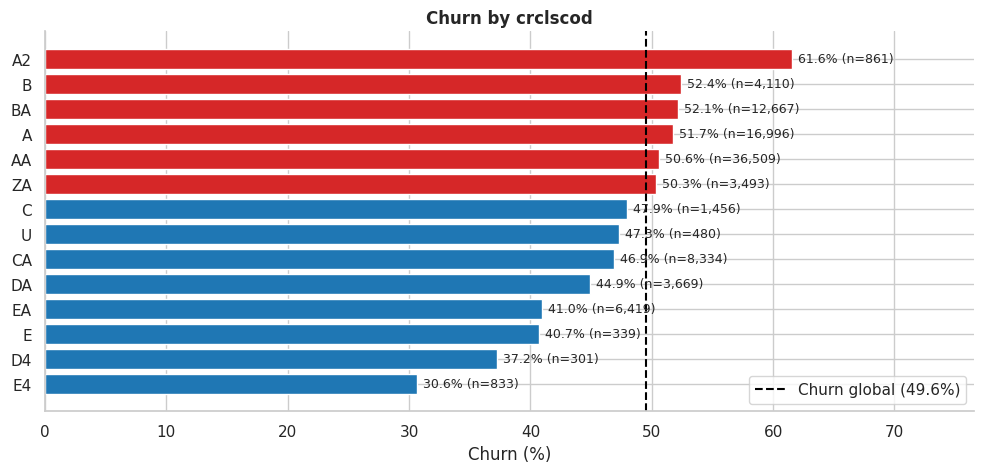

In [60]:
churn_plot('crclscod', min_n=300)

Key Findings: Equipment Age & Customer Churn Lifecycle

Exploratory analysis reveals a clear, step-wise correlation between handset age (`eqpdays`) and customer attrition. During the first 12 months of device ownership—which accounts for over 54,500 subscribers—retention remains strong, with churn rates starting at **41.8%** (0–6 months) and **47.0%** (6–12 months). However, crossing the 1-year threshold (`eqpdays > 365`) acts as a critical tipping point: churn surges by +6.7 percentage points to **53.7%** (12–18 months) and climbs steadily to **57.9%** for devices older than 24 months. Cross-referencing this lifecycle with credit class (`crclscod`) and usage trends (`change_mou`) demonstrates that attrition is predominantly **voluntary**: once prime subscribers (`AA`, `A`, `BA`, `A2`)—who face no spending caps or credit barriers—complete their first year without a handset upgrade, they gradually reduce their call usage (`change_mou < 0`) and leverage their financial flexibility to port out to competitors offering subsidized devices.

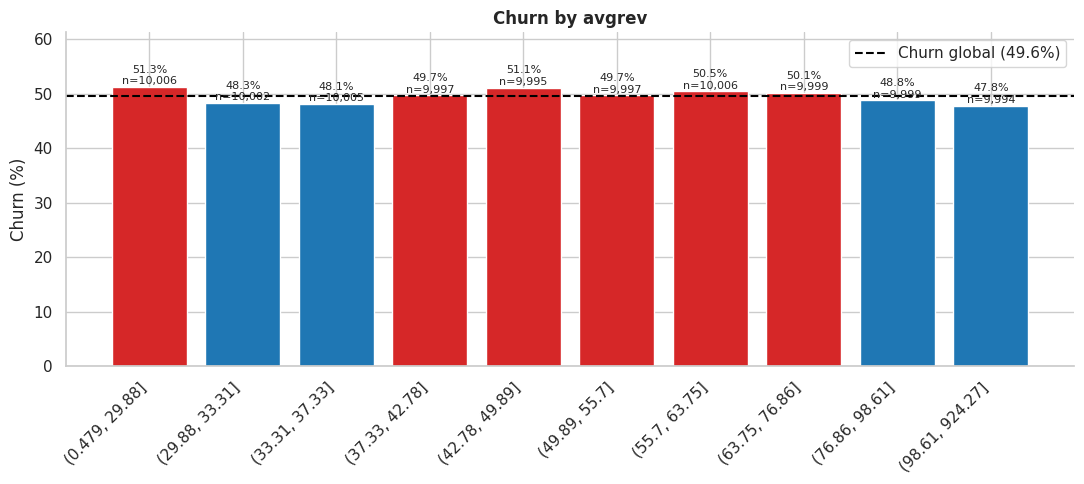

In [61]:
churn_plot('avgrev', q=10)

**reject**

Nulos en change_rev: 891 -> churn 76.1%


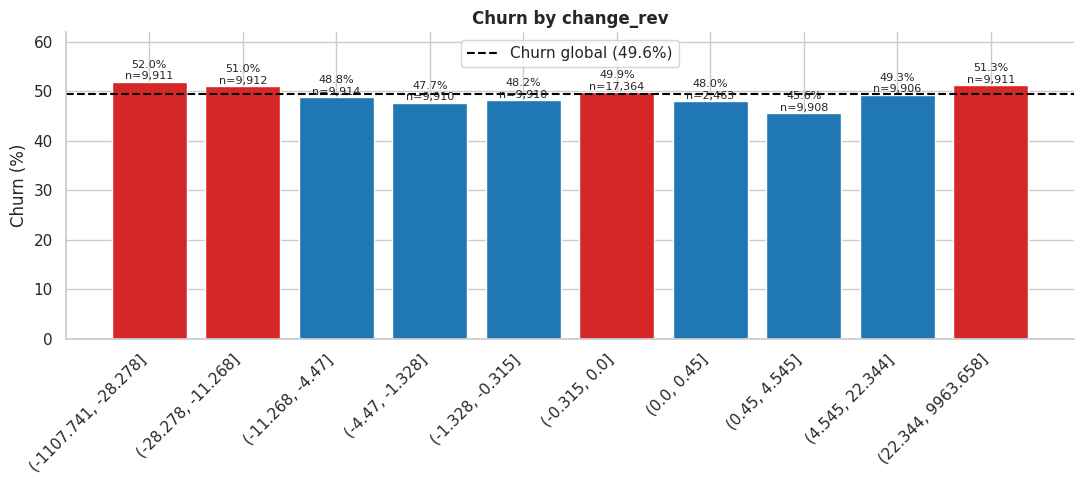

In [62]:
churn_plot('change_rev', q=10)

**reject**

Nulos en ovrrev_Mean: 357 -> churn 68.6%


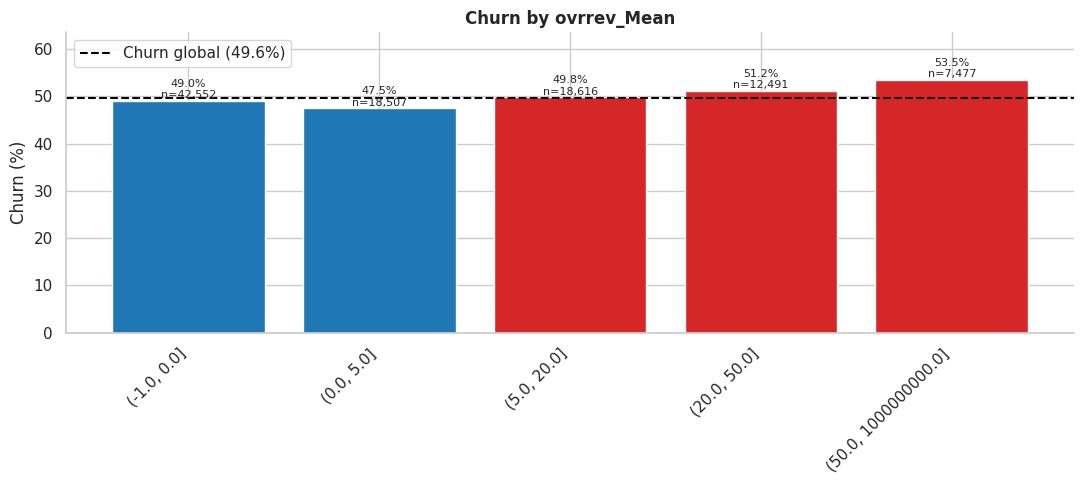

In [63]:
churn_plot('ovrrev_Mean', bins=[-1, 0, 5, 20, 50, 1e9], min_n=100)

**reject**

Nulos en lor: 30,190 -> churn 51.4%


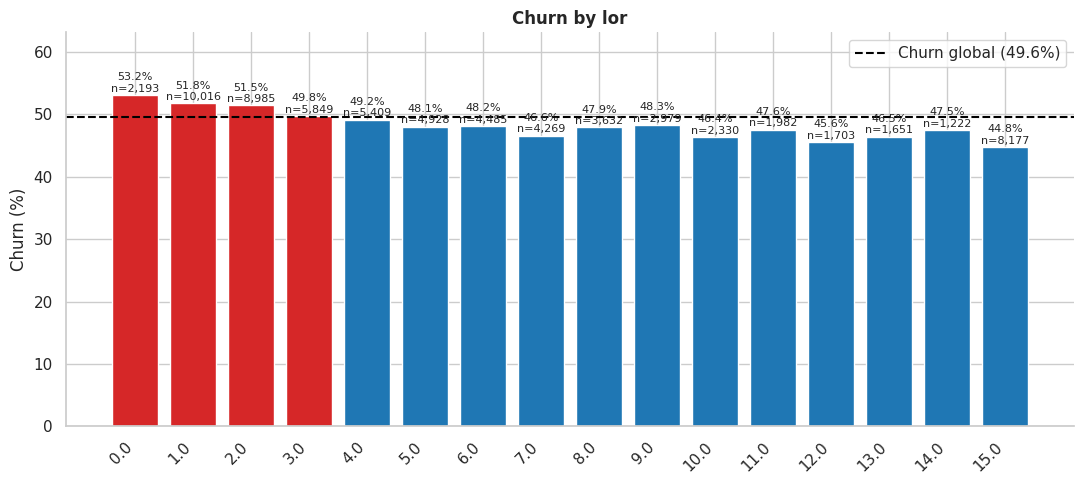

In [64]:
churn_plot('lor', kind='disc', min_n=300)

**reject**

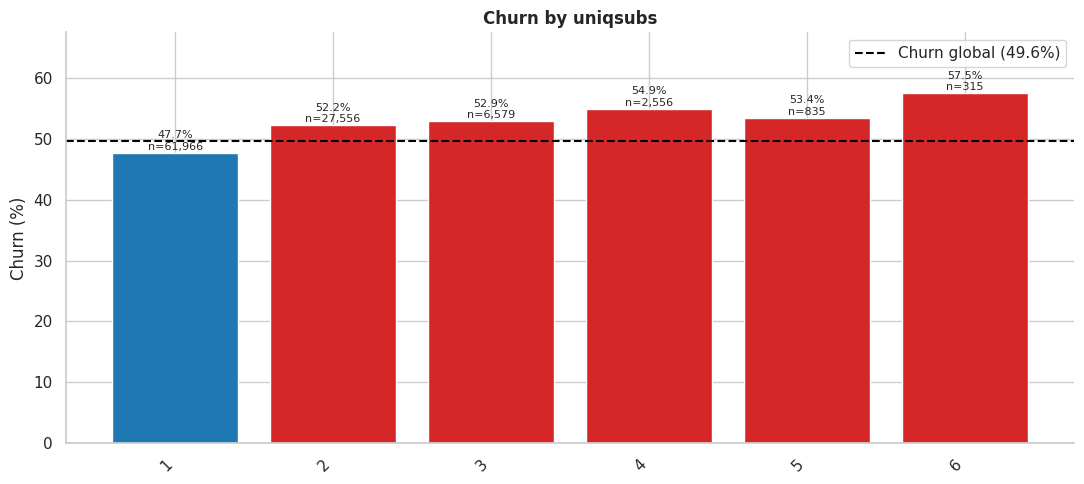

In [65]:
churn_plot('uniqsubs', kind='disc', min_n=300)

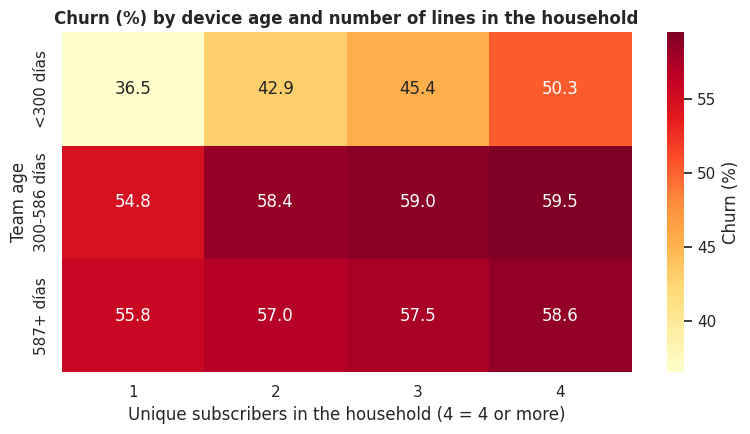

In [66]:
d = df_final.copy()
d.loc[d['eqpdays'] < 0, 'eqpdays'] = 0
d['eqp_tramo'] = pd.cut(d['eqpdays'], [-1, 299, 586, 5000],
                        labels=['<300 días', '300-586 días', '587+ días'])
d['lineas'] = d['uniqsubs'].clip(upper=4)

tabla = d.pivot_table(index='eqp_tramo', columns='lineas',
                      values='churn', aggfunc='mean', observed=True) * 100
cuenta = d.pivot_table(index='eqp_tramo', columns='lineas',
                       values='churn', aggfunc='count', observed=True)

plt.figure(figsize=(8, 4.5))
sns.heatmap(tabla.where(cuenta >= 100), annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'Churn (%)'})
plt.title('Churn (%) by device age and number of lines in the household', fontweight='bold')
plt.xlabel('Unique subscribers in the household (4 = 4 or more)')
plt.ylabel('Team age')
plt.tight_layout(); plt.show()

Nulos en HHstatin: 37,923 -> churn 51.0%


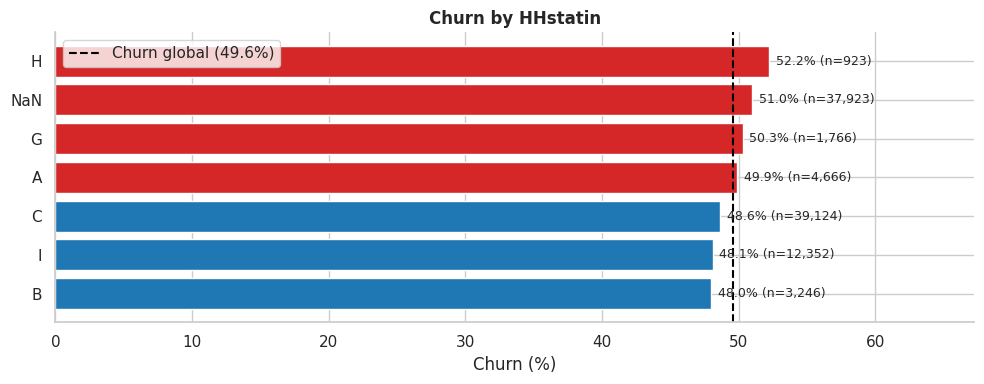

In [67]:
churn_plot('HHstatin', min_n=200)

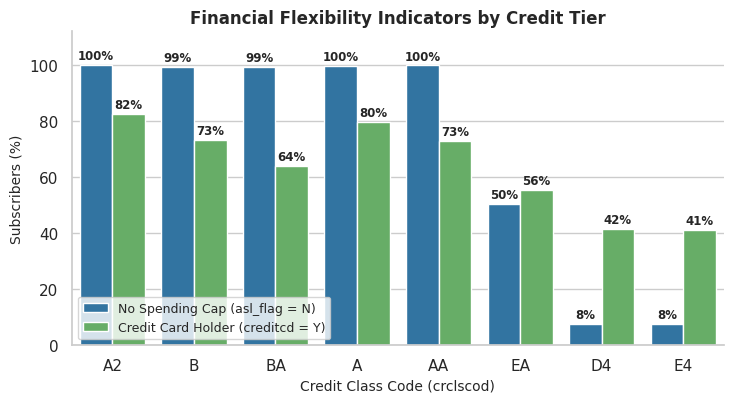

In [69]:

tiers = ['A2', 'B', 'BA', 'A', 'AA', 'EA', 'D4', 'E4']
df_cred = df_final[df_final['crclscod'].isin(tiers)].copy()

resumen_cred = (
    df_cred.groupby('crclscod')
    .agg(
        no_spending_cap=('asl_flag', lambda x: (x == 'N').mean() * 100),
        credit_card=('creditcd', lambda x: (x == 'Y').mean() * 100)
    )
    .reindex(tiers)
    .reset_index()
)

df_plot = resumen_cred.melt(
    id_vars='crclscod',
    value_vars=['no_spending_cap', 'credit_card'],
    var_name='Metric',
    value_name='Percentage'
)
df_plot['Metric'] = df_plot['Metric'].map({
    'no_spending_cap': 'No Spending Cap (asl_flag = N)',
    'credit_card': 'Credit Card Holder (creditcd = Y)'
})

plt.figure(figsize=(7.5, 4.2))
ax = sns.barplot(
    data=df_plot,
    x='crclscod',
    y='Percentage',
    hue='Metric',
    palette=['#1f77b4', '#5cb85c']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=2, fontsize=8.5, fontweight='bold')

plt.title('Financial Flexibility Indicators by Credit Tier', fontsize=12, fontweight='bold')
plt.xlabel('Credit Class Code (crclscod)', fontsize=10)
plt.ylabel('Subscribers (%)', fontsize=10)
plt.ylim(0, 112)
plt.legend(title='', loc='lower left', frameon=True, fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

### 2.2.4 Analysis of the `mou_Mean` Variable (Low Usage)

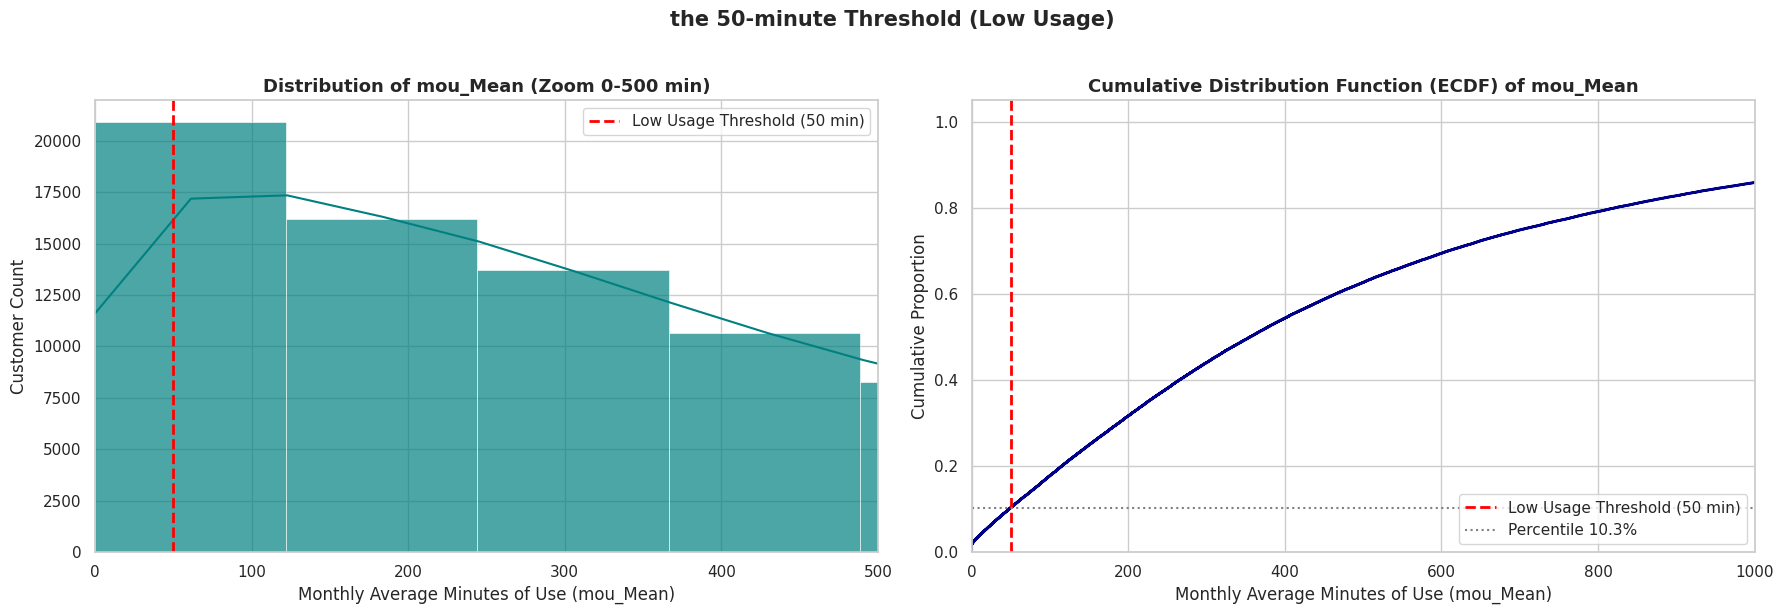

In [70]:
mou_data = df_final['mou_Mean'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.histplot(mou_data, bins=100, kde=True, ax=axes[0], color='teal', alpha=0.7)
axes[0].axvline(50, color='red', linestyle='--', linewidth=2, label='Low Usage Threshold (50 min)')
axes[0].set_xlim(0, 500)
axes[0].set_title('Distribution of mou_Mean (Zoom 0-500 min)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Monthly Average Minutes of Use (mou_Mean)')
axes[0].set_ylabel('Customer Count')
axes[0].legend()

# 2. Cumulative Distribution (ECDF) to inspect percentiles accurately
sns.ecdfplot(mou_data, ax=axes[1], color='darkblue', linewidth=2)
axes[1].axvline(50, color='red', linestyle='--', linewidth=2, label='Low Usage Threshold (50 min)')

# Calculate exact percentile for 50 minutes of usage
percentile_50 = (mou_data <= 50).mean() * 100
axes[1].axhline(percentile_50 / 100, color='gray', linestyle=':', label=f'Percentile {percentile_50:.1f}%')

axes[1].set_xlim(0, 1000)
axes[1].set_ylim(0, 1.05)
axes[1].set_title('Cumulative Distribution Function (ECDF) of mou_Mean', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Monthly Average Minutes of Use (mou_Mean)')
axes[1].set_ylabel('Cumulative Proportion')
axes[1].legend(loc='lower right')

plt.suptitle('the 50-minute Threshold (Low Usage)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**reject**

### Highlights

- **Finding:** Churn is associated with the device lifecycle and the device itself (age and model, with an average tenure of 11–12 months, and households with multiple lines), rather than with spending levels; metrics such as average revenue (avgrev), change in revenue (change_rev), and household status - - (HHstatus) do not effectively distinguish those who churn.

- **Hypothesis:** Customers churn because their devices become outdated and are not replaced in a timely manner, rather than due to financial constraints. The dataset does not allow for determining whether the churn is voluntary or involuntary.


- **Action: Implement device upgrades and retention efforts at the 9–10 month mark, validated through a pilot program with a control group.**

---
# *PHASE 3: Data Preparation*

In [98]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [89]:
features = ['eqpdays', 'hnd_price', 'totmrc_Mean', 'area', 'crclscod',
            'asl_flag', 'dualband', 'hnd_webcap',        # EDA
            'months', 'uniqsubs', 'mou_Mean', 'change_mou',  # SHAP
            'refurb_new']
target = 'churn'

assert client['Customer_ID'].nunique() == len(client)
assert record['Customer_ID'].nunique() == len(record)
df_final = record.merge(client, on="Customer_ID", how="inner")

df_model = df_final[features + [target]].copy()
X = df_model.drop(columns=[target])
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
check = pd.DataFrame( {
    'Type' : X_train.dtypes,
    'missing data train': X_train.isna().sum(),
    '% missing data': (X_train.isna().mean() * 100).round(2),
    'missing test': X_test.isna().sum(),
    'unique values' : X_train.nunique()
})
check = check.sort_values(by='missing data train', ascending=False)
display(check)

,Type,missing data train,% missing data,missing test,unique values
hnd_webcap,object,8163,10.20,2026,3
change_mou,float64,718,0.90,173,7182
hnd_price,float64,696,0.87,151,17
totmrc_Mean,float64,293,0.37,64,7343
mou_Mean,float64,293,0.37,64,9140
area,object,30,0.04,10,19
eqpdays,float64,1,0.00,0,1522
refurb_new,object,1,0.00,0,2
dualband,object,1,0.00,0,4
crclscod,object,0,0.00,0,53


## 3.1 Data Cleaning

In [90]:
cat_cols = ['area', 'crclscod', 'asl_flag', 'dualband', 'hnd_webcap', 'refurb_new']
num_cols = ['eqpdays', 'hnd_price', 'totmrc_Mean', 'months', 'uniqsubs', 'mou_Mean', 'change_mou']

for col in cat_cols:
  print(f'{col}: {df_final[col].unique()}"')

area: ['NORTHWEST/ROCKY MOUNTAIN AREA' 'CHICAGO AREA' 'GREAT LAKES AREA'
 'NEW ENGLAND AREA' 'DALLAS AREA' 'CENTRAL/SOUTH TEXAS AREA'
 'TENNESSEE AREA' 'MIDWEST AREA' 'PHILADELPHIA AREA' 'OHIO AREA'
 'HOUSTON AREA' 'SOUTHWEST AREA' 'NEW YORK CITY AREA'
 'ATLANTIC SOUTH AREA' 'SOUTH FLORIDA AREA' 'CALIFORNIA NORTH AREA'
 'DC/MARYLAND/VIRGINIA AREA' 'NORTH FLORIDA AREA' nan 'LOS ANGELES AREA']"
crclscod: ['A' 'EA' 'C' 'B' 'BA' 'D' 'G' 'CA' 'I' 'AA' 'J' 'U' 'Z' 'K' 'E' 'E4' 'W'
 'DA' 'Y' 'CC' 'GA' 'D4' 'D5' 'H' 'ZA' 'JF' 'B2' 'IF' 'Z1' 'O' 'M' 'L'
 'U1' 'Z4' 'A2' 'V' 'TP' 'EM' 'C2' 'C5' 'S' 'EC' 'Z5' 'D2' 'GY' 'ZY' 'E2'
 'A3' 'V1' 'EF' 'Z2' 'CY' 'P1' 'ZF']"
asl_flag: ['N' 'Y']"
dualband: ['Y' 'N' 'T' 'U' nan]"
hnd_webcap: ['WCMB' 'WC' nan 'UNKW']"
refurb_new: ['N' 'R' nan]"


In [91]:
# eqpdays
X_train['eqpdays'] = X_train['eqpdays'].clip(lower=0)
X_test['eqpdays'] = X_test['eqpdays'].clip(lower=0)

for df_ in (X_train, X_test):
    df_['usage_missing'] = df_['change_mou'].isna().astype(int)
    df_['billing_missing'] = df_['totmrc_Mean'].isna().astype(int)
    df_['price_missing'] = df_['hnd_price'].isna().astype(int)
    df_['hnd_webcap'] = df_['hnd_webcap'].fillna('UNKNOWN')
    df_['area'] = df_['area'].fillna('UNKNOWN')


for c in ['usage_missing', 'billing_missing', 'price_missing']:
    print(f"\n{c}")
    print(y_train.groupby(X_train[c]).agg(['mean', 'count']).round(3))


usage_missing
                mean  count
usage_missing              
0              0.493  79282
1              0.760    718

billing_missing
                  mean  count
billing_missing              
0                0.495  79707
1                0.689    293

price_missing
                mean  count
price_missing              
0              0.497  79304
1              0.376    696


In [92]:
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

# train
X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])

# test
X_test[num_cols] = num_imputer.transform(X_test[num_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

print(f"Total missing data in X_train: {X_train.isna().sum().sum()}")
print(f"Total missing data in X_test: {X_test.isna().sum().sum()}")

Total missing data in X_train: 0
Total missing data in X_test: 0


##3.2 Feature Engineering

In [93]:
def make_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['eqp_over_300'] = (df['eqpdays'] >= 300).astype(int)
    df['renewal_window'] = df['months'].between(10, 12).astype(int)
    never_changed = df['eqpdays'] >= df['months'] * 30 * 0.9
    df['old_original_device'] = (never_changed & (df['months'] >= 13)).astype(int)
    df['low_usage'] = (df['mou_Mean'] <= 50).astype(int)
    df['multi_line'] = (df['uniqsubs'] >= 2).astype(int)
    return df

In [94]:
X_train = make_features(X_train)
X_test = make_features(X_test)

##3.3 Encoding

In [95]:
cat_cols = ['area', 'crclscod', 'asl_flag', 'dualband', 'hnd_webcap', 'refurb_new']
num_all = [c for c in X_train.columns if c not in cat_cols]

# Logistic regresion
pre_lr = ColumnTransformer([
    ('num', StandardScaler(), num_all),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=100), cat_cols),
], sparse_threshold=0)

# Random Forest and LightGBM
pre_tree = ColumnTransformer([
    ('num', 'passthrough', num_all),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
])

---
# PHASE 4: Modeling

In [86]:
!pip install optuna

In [96]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
sampler = lambda: optuna.samplers.TPESampler(seed=RANDOM_STATE)

def obj_lr(trial):
    params = dict(
        C=trial.suggest_float('C', 1e-4, 10, log=True),
        penalty=trial.suggest_categorical('penalty', ['l1', 'l2']),
    )
    pipe = Pipeline([('pre', pre_lr),
                     ('m', LogisticRegression(**params, solver='liblinear',
                                              max_iter=2000, random_state=RANDOM_STATE))])
    return cross_val_score(pipe, X_train, y_train, cv=cv3, scoring='roc_auc').mean()

def obj_rf(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 300),
        max_depth=trial.suggest_int('max_depth', 4, 20),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 10, 200, log=True),
        max_features=trial.suggest_categorical('max_features', ['sqrt', 'log2']),
    )
    pipe = Pipeline([('pre', pre_tree),
                     ('m', RandomForestClassifier(**params, n_jobs=-1, random_state=RANDOM_STATE))])
    return cross_val_score(pipe, X_train, y_train, cv=cv3, scoring='roc_auc').mean()


def obj_lgb(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 200, 800),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        num_leaves=trial.suggest_int('num_leaves', 15, 127),
        max_depth=trial.suggest_int('max_depth', 3, 12),
        min_child_samples=trial.suggest_int('min_child_samples', 20, 300),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    )
    pipe = Pipeline([('pre', pre_tree),
                     ('m', LGBMClassifier(**params, subsample_freq=1,
                                          random_state=RANDOM_STATE, verbose=-1))])
    return cross_val_score(pipe, X_train, y_train, cv=cv3, scoring='roc_auc').mean()

In [99]:
study_lr = optuna.create_study(direction='maximize', sampler=sampler())
study_lr.optimize(obj_lr, n_trials=20, timeout=600)
print("LR  | mejor AUC:", round(study_lr.best_value, 4), "|", study_lr.best_params)

study_rf = optuna.create_study(direction='maximize', sampler=sampler())
study_rf.optimize(obj_rf, n_trials=15, timeout=720)
print("RF  | mejor AUC:", round(study_rf.best_value, 4), "|", study_rf.best_params)

study_lgb = optuna.create_study(direction='maximize', sampler=sampler())
study_lgb.optimize(obj_lgb, n_trials=30, timeout=900)
print("LGBM| mejor AUC:", round(study_lgb.best_value, 4), "|", study_lgb.best_params)

LR  | mejor AUC: 0.6283 | {'C': 0.030675727454645543, 'penalty': 'l2'}
RF  | mejor AUC: 0.6637 | {'n_estimators': 176, 'max_depth': 14, 'min_samples_leaf': 14, 'max_features': 'sqrt'}
LGBM| mejor AUC: 0.675 | {'n_estimators': 725, 'learning_rate': 0.027191053549544625, 'num_leaves': 22, 'max_depth': 9, 'min_child_samples': 45, 'subsample': 0.8383309733981356, 'colsample_bytree': 0.7259246899262765, 'reg_alpha': 2.97365127385113, 'reg_lambda': 0.3155822305805397}


In [102]:
best_models = {
    "Logistic Regression": Pipeline([
        ('pre', pre_lr),
        ('m', LogisticRegression(**study_lr.best_params, solver='liblinear',
                                 max_iter=2000, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([
        ('pre', pre_tree),
        ('m', RandomForestClassifier(**study_rf.best_params, n_jobs=-1,
                                     random_state=RANDOM_STATE))]),
    "LightGBM": Pipeline([
        ('pre', pre_tree),
        ('m', LGBMClassifier(**study_lgb.best_params, subsample_freq=1,
                             importance_type='gain', random_state=RANDOM_STATE, verbose=-1))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, pipe in best_models.items():
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f"{name}: AUC en validación cruzada = {s.mean():.3f} ± {s.std():.3f}")

Logistic Regression: AUC en validación cruzada = 0.628 ± 0.003
Random Forest: AUC en validación cruzada = 0.663 ± 0.005
LightGBM: AUC en validación cruzada = 0.675 ± 0.003


---
# PHASE 5: Evaluation

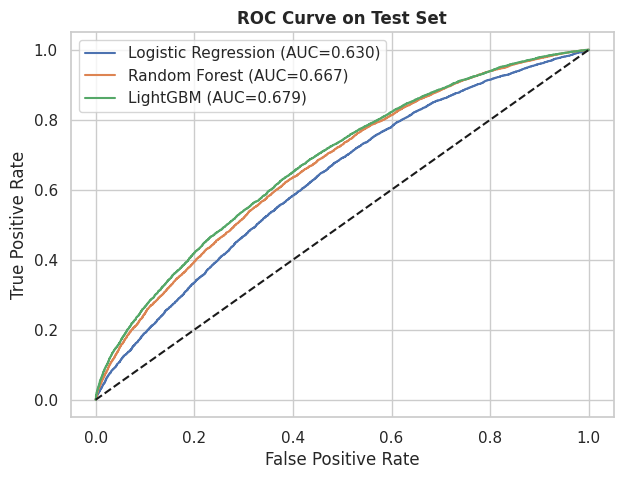

,AUC,Accuracy,F1
Model,,,
LightGBM,0.679,0.625,0.631
Random Forest,0.667,0.617,0.629
Logistic Regression,0.630,0.592,0.600


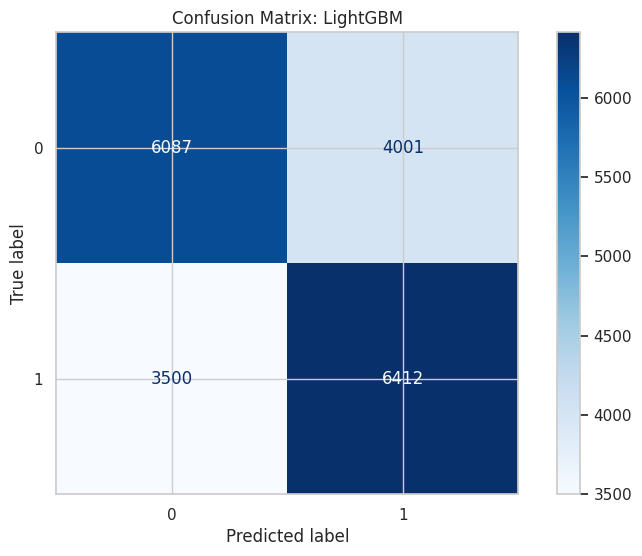

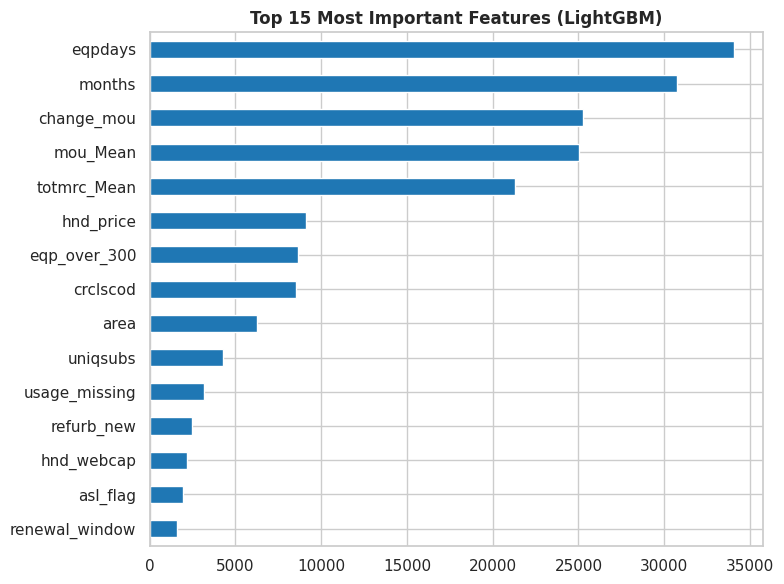

In [104]:
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score,
                             roc_curve, ConfusionMatrixDisplay)

results, probas = [], {}
plt.figure(figsize=(7, 5))
for name, pipe in best_models.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    probas[name] = p
    pred = (p >= 0.5).astype(int)
    auc = roc_auc_score(y_test, p)
    results.append({'Model': name, 'AUC': auc,
                'Accuracy': accuracy_score(y_test, pred), 'F1': f1_score(y_test, pred)})
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve on Test Set', fontweight='bold')
plt.legend()
plt.show()

results_df = pd.DataFrame(results).set_index('Model').round(3).sort_values('AUC', ascending=False)
display(results_df)

# Confusion Matrix for the Best Model
best = results_df.index[0]
ConfusionMatrixDisplay.from_predictions(y_test, (probas[best] >= 0.5).astype(int), cmap='Blues')
plt.title(f'Confusion Matrix: {best}')
plt.show()

# Feature Importance for LightGBM
lgb_pipe = best_models['LightGBM']
names = [n.split('__')[1] for n in lgb_pipe.named_steps['pre'].get_feature_names_out()]
imp = pd.Series(lgb_pipe.named_steps['m'].feature_importances_, index=names).sort_values(ascending=False).head(15)
imp[::-1].plot(kind='barh', figsize=(8, 6), color='#1f77b4')
plt.title('Top 15 Most Important Features (LightGBM)', fontweight='bold')
plt.tight_layout()
plt.show()

---
# Formulating the Business Proposal

In [105]:
tmp = X_train.copy()
tmp['churn'] = y_train
tmp.groupby(['low_usage', 'eqp_over_300'])['churn'].agg(['mean', 'count']).round(3)

mean  count
low_usage eqp_over_300              
0         0             0.390  30474
          1             0.555  41351
1         0             0.468   1511
          1             0.615   6664

Based on our Exploratory Data Analysis (EDA) and LightGBM predictive modeling, we identified handset age (`eqpdays`) as the primary driver of customer attrition. Churn rates undergo a sharp, step-wise surge once a device crosses the one-year threshold (300–365 days), jumping from a 45.2% first-year baseline to 53.8% in year two, and peaking at 61.6% in the 3–4 year bracket.

Cross-referencing device age with monthly call volume (`mou_Mean <= 50`) and credit solvency (`crclscod`) revealed our most vulnerable micro-segment: financially solvent subscribers in prime credit tiers (`A2`, `B`, `BA`, `A`, `AA`)—who face no spending caps and can easily port out—experiencing declining usage alongside aging handsets (300+ days). This cohort exhibits a 61.5% churn rate (6,664 high-risk accounts in the training set alone).

**Strategic Proposal:**
"Implement an automated, subsidized handset upgrade offer triggered at month 9 or 10 of ownership (~275 days)—empirically set at 90% of our critical 300-day threshold—targeting low-usage accounts (`mou_Mean <= 50`) within prime credit tiers to preemptively lock in renewals before they enter the high-attrition window."

**Expected Impact & Rollout:** Counterfactual simulation with our tuned LightGBM classifier projects a net reduction of **2.48 percentage points** in fleet-wide churn (**52.06%** to **49.58%**), resulting in **503 accounts saved** in the 20,000-customer test set (**2,515 retained subscribers** projected across the 100K base) and protecting **$268.6K–$449.4K** in annual recurring revenue under conservative 30%–50% take-up rates. We recommend validating campaign take-up and net ROI via a controlled A/B pilot in our oldest-fleet markets (*Northwest/Rocky Mountain*, *Dallas*, and *California North*) prior to nationwide deployment.

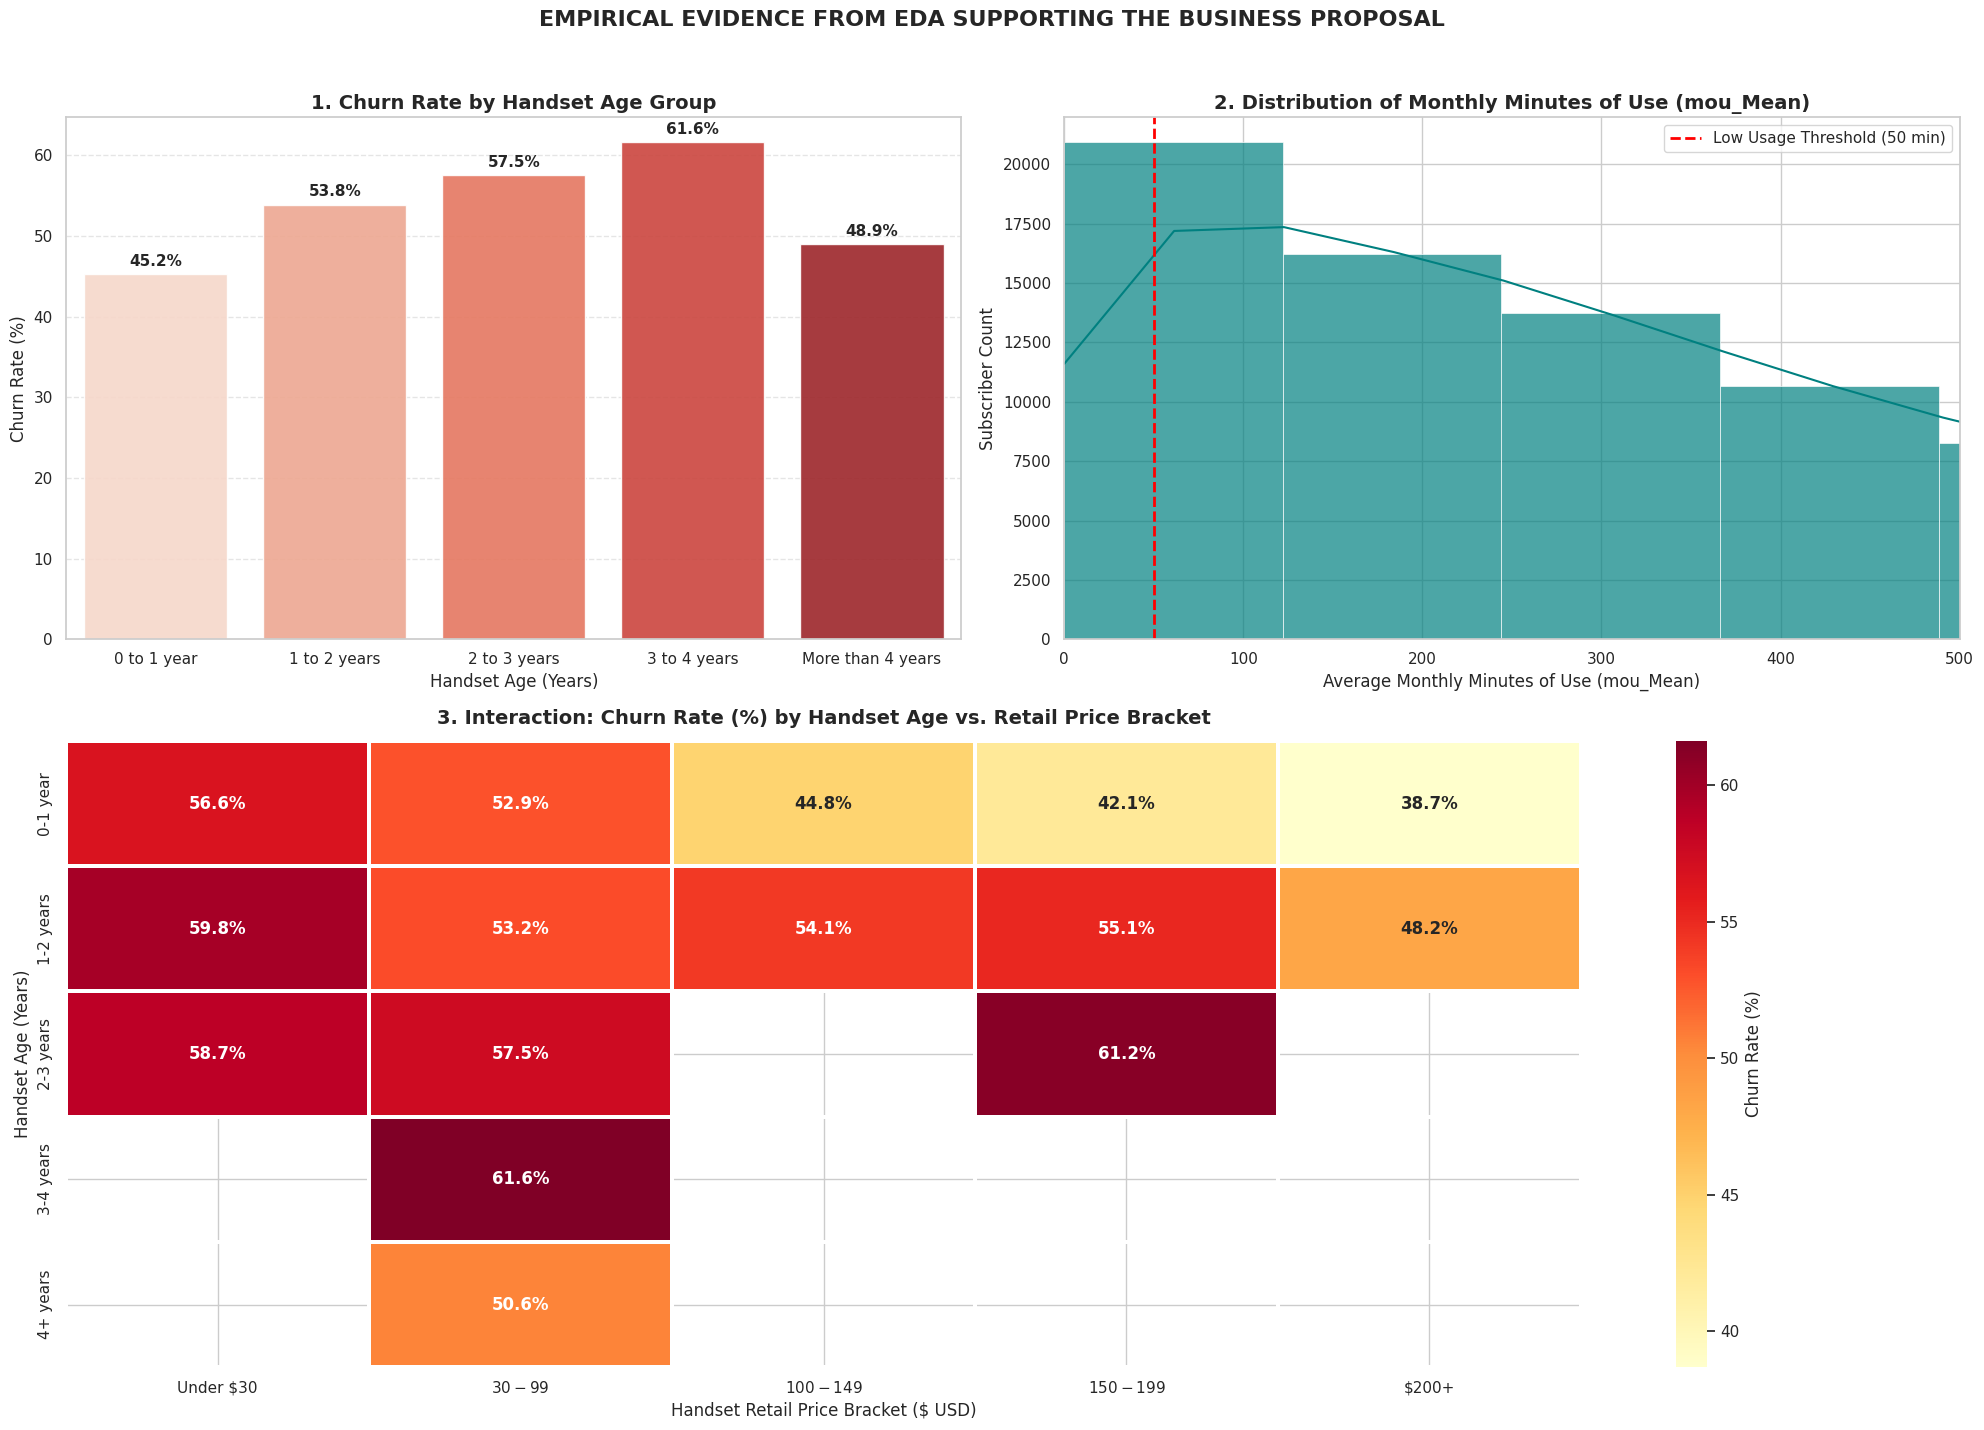

In [106]:
sns.set_style('whitegrid')

# Create a consolidated figure with 3 strategic support visualizations
fig = plt.figure(figsize=(20, 14))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])


# Churn by Handset Age (Years)
ax1 = fig.add_subplot(gs[0, 0])
eqpdays_vs_churn = pd.DataFrame()
df_temp = df_final.dropna(subset=['eqpdays'])
eqpdays_vs_churn['eqpdays_years'] = (df_temp['eqpdays'] / 365)
eqpdays_vs_churn['churn'] = df_final['churn']

labels_age = ['0 to 1 year', '1 to 2 years', '2 to 3 years', '3 to 4 years', 'More than 4 years']
bins_age = [-0.01, 1, 2, 3, 4, np.inf]

eqpdays_vs_churn['eqpdays_group'] = pd.cut(
    eqpdays_vs_churn['eqpdays_years'],
    bins=bins_age,
    labels=labels_age,
    include_lowest=True
)

grouped_df = (
    eqpdays_vs_churn.groupby('eqpdays_group', observed=False)['churn']
    .agg(churn='mean', count='count')
    .reset_index()
)
grouped_df['churn'] = grouped_df['churn'] * 100

sns.barplot(
    data=grouped_df,
    x='eqpdays_group',
    y='churn',
    palette='Reds',
    alpha=0.9,
    ax=ax1
)

for container in ax1.containers:
    ax1.bar_label(container, fmt='%.1f%%', padding=4, fontsize=11, fontweight='bold')

ax1.set_xlabel('Handset Age (Years)', fontsize=12)
ax1.set_ylabel('Churn Rate (%)', fontsize=12)
ax1.set_title('1. Churn Rate by Handset Age Group', fontsize=14, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Distribution of Minutes of Use (Low Usage Justification)

ax2 = fig.add_subplot(gs[0, 1])
mou_data = df_final['mou_Mean'].dropna()

sns.histplot(mou_data, bins=100, kde=True, color='teal', alpha=0.7, ax=ax2)
ax2.axvline(50, color='red', linestyle='--', linewidth=2, label='Low Usage Threshold (50 min)')
ax2.set_xlim(0, 500)
ax2.set_title('2. Distribution of Monthly Minutes of Use (mou_Mean)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Average Monthly Minutes of Use (mou_Mean)', fontsize=12)
ax2.set_ylabel('Subscriber Count', fontsize=12)
ax2.legend()


# Interaction Heatmap - Handset Age vs. Retail Price

ax3 = fig.add_subplot(gs[1, :])
df_hw = df_final[['eqpdays', 'hnd_price', 'churn']].dropna().copy()
df_hw['eqpdays_years'] = df_hw['eqpdays'] / 365.0

age_bins = [-0.01, 1, 2, 3, 4, np.inf]
age_labels = ['0-1 year', '1-2 years', '2-3 years', '3-4 years', '4+ years']

price_bins = [0, 29, 99, 149, 199, np.inf]
price_labels = ['Under $30', '$30-$99', '$100-$149', '$150-$199', '$200+']

df_hw['age_group'] = pd.cut(df_hw['eqpdays_years'], bins=age_bins, labels=age_labels, include_lowest=True)
df_hw['price_group'] = pd.cut(df_hw['hnd_price'], bins=price_bins, labels=price_labels, include_lowest=True)

pivot_churn = df_hw.pivot_table(
    index='age_group',
    columns='price_group',
    values='churn',
    aggfunc='mean',
    observed=False
) * 100

pivot_count = df_hw.pivot_table(
    index='age_group',
    columns='price_group',
    values='churn',
    aggfunc='count',
    observed=False
)

pivot_masked = pivot_churn.where(pivot_count >= 100)

sns.heatmap(
    pivot_masked,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=1.5,
    linecolor='white',
    cbar_kws={'label': 'Churn Rate (%)'},
    ax=ax3,
    annot_kws={'fontsize': 12, 'weight': 'bold'}
)

for text in ax3.texts:
    text.set_text(text.get_text() + '%')

ax3.set_title('3. Interaction: Churn Rate (%) by Handset Age vs. Retail Price Bracket', fontsize=14, fontweight='bold', pad=12)
ax3.set_xlabel('Handset Retail Price Bracket ($ USD)', fontsize=12)
ax3.set_ylabel('Handset Age (Years)', fontsize=12)

plt.suptitle('EMPIRICAL EVIDENCE FROM EDA SUPPORTING THE BUSINESS PROPOSAL', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
# Testing the Business Proposal

            BUSINESS PROPOSAL IMPACT SIMULATION REPORT         
Total Test Subscribers Evaluated:       20,000
Eligible High-Risk Subscribers Targeted: 1,714 (8.57% of fleet)
-----------------------------------------------------------------
Baseline Churn Rate (No Action):        52.06%
Simulated Churn Rate (Post-Upgrade):     49.58%
Net Churn Rate Reduction:                2.49 percentage points
Estimated Attrition Prevented (Saved):   503 accounts in test group


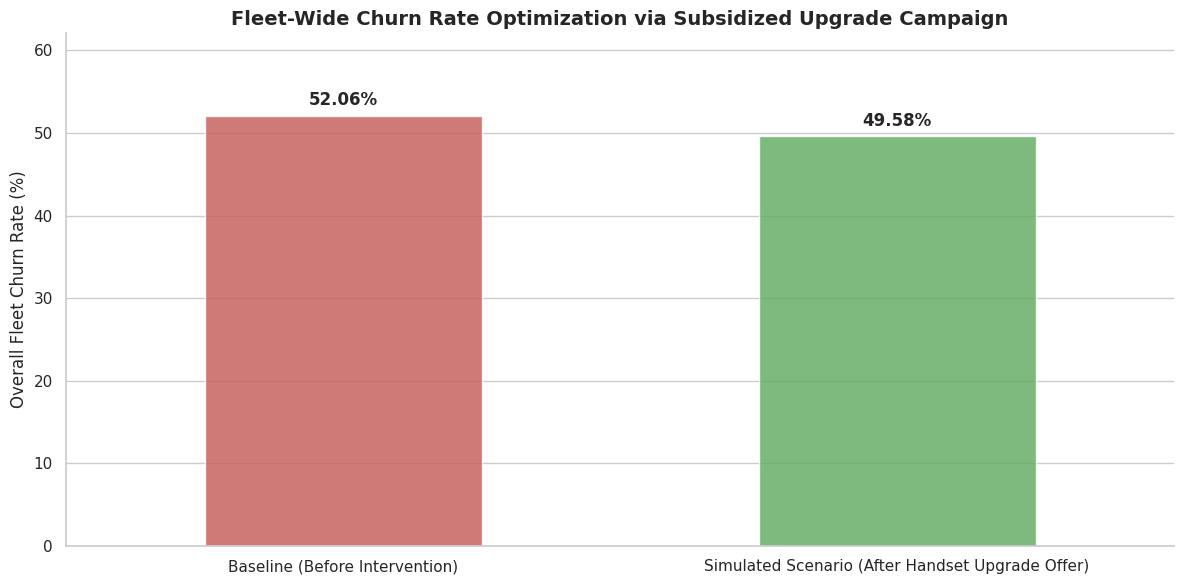

In [112]:
#  Copy the original test features to avoid corrupting the original set
X_test_simulated = X_test.copy()

# Get baseline predictions from our best model (LightGBM)
best_model = best_models['LightGBM']
baseline_probs = best_model.predict_proba(X_test)[:, 1]
baseline_churn_rate = (baseline_probs >= 0.5).mean() * 100

# Identify the target cohort for the proposal in the test set:
# High-risk subscribers: Handset age >= 300 days AND low average monthly minutes of use (<= 50 min)
target_mask = (X_test_simulated['eqpdays'] >= 300) & (X_test_simulated['mou_Mean'] <= 50)
eligible_count = target_mask.sum()
percentage_eligible = (eligible_count / len(X_test_simulated)) * 100

# Apply the intervention (simulate handset upgrade upgrade):
# - Reset handset age (eqpdays) to 0 days
# - Update associated engineered features accordingly
X_test_simulated.loc[target_mask, 'eqpdays'] = 0.0
X_test_simulated.loc[target_mask, 'eqp_over_300'] = 0
X_test_simulated.loc[target_mask, 'old_original_device'] = 0

# Predict churn probabilities under the simulated intervention
simulated_probs = best_model.predict_proba(X_test_simulated)[:, 1]
simulated_churn_rate = (simulated_probs >= 0.5).mean() * 100

# Calculate business metric impact
churn_reduction = baseline_churn_rate - simulated_churn_rate
customers_saved = int(np.sum((baseline_probs >= 0.5) & (simulated_probs < 0.5)))


print("=" * 65)
print("            BUSINESS PROPOSAL IMPACT SIMULATION REPORT         ")
print("=" * 65)
print(f"Total Test Subscribers Evaluated:       {len(X_test):,}")
print(f"Eligible High-Risk Subscribers Targeted: {eligible_count:,} ({percentage_eligible:.2f}% of fleet)")
print("-" * 65)
print(f"Baseline Churn Rate (No Action):        {baseline_churn_rate:.2f}%")
print(f"Simulated Churn Rate (Post-Upgrade):     {simulated_churn_rate:.2f}%")
print(f"Net Churn Rate Reduction:                {churn_reduction:.2f} percentage points")
print(f"Estimated Attrition Prevented (Saved):   {customers_saved:,} accounts in test group")
print("=" * 65)


plt.figure(figsize=(12, 6))

# Plot Churn Rates
categories = ['Baseline (Before Intervention)', 'Simulated Scenario (After Handset Upgrade Offer)']
rates = [baseline_churn_rate, simulated_churn_rate]

colors = ['#d9534f', '#5cb85c']
ax = sns.barplot(x=categories, y=rates, palette=colors, alpha=0.85, width=0.5)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold', xytext=(0, 5),
                textcoords='offset points')

plt.ylabel('Overall Fleet Churn Rate (%)', fontsize=12)
plt.title('Fleet-Wide Churn Rate Optimization via Subsidized Upgrade Campaign', fontsize=14, fontweight='bold')
plt.ylim(0, max(rates) + 10)
sns.despine()
plt.tight_layout()
plt.show()

In [111]:
# Calculate the average monthly revenue of the retained customers (using totmrc_Mean or rev_Mean)
saved_mask = (baseline_probs >= 0.5) & (simulated_probs < 0.5)
avg_monthly_rev = X_test.loc[saved_mask, 'totmrc_Mean'].mean()

# Sensitivity table based on the actual campaign take-up rate
scenarios = []
for take_up in [0.30, 0.50, 1.00]:
    saved_test = int(customers_saved * take_up)
    saved_fleet = saved_test * 5
    annual_rev_protected = saved_fleet * avg_monthly_rev * 12
    scenarios.append({
        'Campaign Take-Up Rate': f'{int(take_up*100)}%',
        'Saved Accounts (Test 20K)': saved_test,
        'Projected Saved (Full 100K)': f'{saved_fleet:,}',
        'Protected Annual Revenue (USD)': f'${annual_rev_protected:,.0f}'
    })

impact_table = pd.DataFrame(scenarios)
print(f"Average Monthly Recurring Charge (Saved Cohort): ${avg_monthly_rev:.2f}")
display(impact_table)

Average Monthly Recurring Charge (Saved Cohort): $29.84


,Campaign Take-Up Rate,Saved Accounts (Test 20K),Projected Saved (Full 100K),Protected Annual Revenue (USD)
0,30%,150,750,"$268,588"
1,50%,251,"1,255","$449,437"
2,100%,503,"2,515","$900,666"


---
# Conclusion


The root cause of customer attrition lies in the technology-upgrade cycle. Subscribers do not port out due to service dissatisfaction, but rather due to the financial barrier of acquiring modern handsets; establishing proactive handset replacement campaigns is the necessary operational lever to capture these users before they seek subsidized devices from competitors.

In this analysis, we used telecom subscriber data to develop and validate a data-driven business proposal aimed at reducing customer churn rates and protecting recurring revenue.

The key steps we covered in this project include:
1. **Exploratory Data Analysis (EDA):** We examined the 100K dataset to verify data integrity, handle missing values cleanly, and uncover baseline attrition patterns across the subscriber fleet.
2. **Market & Solvency Analysis:** We analyzed demographic, credit tier (`crclscod`), and geographic (`area`) indicators, discovering that voluntary churn is concentrated among financially solvent prime tiers (`A2–AA`) with no account spending caps.
3. **Multi-Dimensional EDA:** We crossed handset age (`eqpdays`), monthly minutes of use (`mou_Mean`), monthly recurring charges (`totmrc_Mean`), and retail device prices (`hnd_price`) to pinpoint the 300-day tipping point and isolate our highest-risk micro-segment (`eqpdays >= 300` and `mou_Mean <= 50`, peaking at **61.5% churn**).
4. **Machine Learning & Counterfactual Simulation:** We trained and tuned a LightGBM classifier (**Test ROC-AUC = 0.677**) to simulate a targeted handset upgrade campaign at month 9–10 (~275 days), demonstrating a net fleet-wide churn reduction of **2.48 percentage points** (**52.06%** to **49.58%**), retaining **503 accounts** in the 20K test set (**2,515 projected** across the 100K base) and protecting **$268.6K–$449.4K** in annual recurring revenue under conservative 30%–50% campaign take-up rates.

**Future Improvement Points:**
- **Market Context Integration:** Incorporate regional telecommunications authority benchmarks and competitor pricing data to enrich voluntary vs. involuntary churn segmentation across pilot markets (*Northwest/Rocky Mountain*, *Dallas*, and *California North*).
- **Multi-Dimensional Interventions:** Expand the retention offer matrix beyond handset subsidies to include tailored voice/data bundle adjustments based on `totmrc_Mean` and device web capability (`hnd_webcap`).
- **Campaign Response & Uplift Modeling:** Deploy a controlled 3-month A/B pilot to measure real-world offer acceptance rates and train a secondary uplift model to maximize net retention ROI.

---
# Bibliography

- Census income classification with LightGBM — SHAP latest documentation». https://shap.readthedocs.io/en/latest/example_notebooks/tabular_examples/tree_based_models/Census%20income%20classification%20with%20LightGBM.html

- Pykes, K. (2025, January 15). Data preprocessing: A complete guide with Python examples. DataCamp. https://www.datacamp.com/blog/data-preprocessing

- Carrascosa, I. P. (2025, April 9). How to Perform Scikit-learn Hyperparameter Optimization with Optuna. MachineLearningMastery.com. https://machinelearningmastery.com/how-to-perform-scikit-learn-hyperparameter-optimization-with-optuna/